# Laboratorio #9 — Series de tiempo y forecasting

**CC3092 · Deep Learning y Sistemas Inteligentes** — Universidad del Valle de Guatemala

**Nicolás Concuá y Esteban** · Guatemala, octubre de 2026

Repositorio: https://github.com/nicoCT04/Lab9-DL

Pronóstico *day-ahead* (H = 24 h) del consumo eléctrico horario de clientes de Portugal
(**ElectricityLoadDiagrams20112014**, UCI). El notebook construye el pipeline completo
**datos crudos → series horarias limpias → ventanas → tensores → modelo → backtest**, implementa un único
protocolo de evaluación `backtest(modelo)` con origen móvil diario (92 orígenes en oct–dic 2014) y compara
baselines estadísticos, modelos propios en PyTorch (MLP, DLinear, NLinear, LSTM, seq2seq) y modelos de librería.

## 0. Configuración del entorno

**Hardware:** la ejecución final de este notebook (la que se entrega) corrió en una laptop con Intel Core i9-13980HX y GPU **NVIDIA RTX 4050 Laptop (6 GB, CUDA)**; la columna `hardware` de las tablas lo registra modelo por modelo. El desarrollo inicial se hizo en un Apple M4 Pro (backend **MPS**). El código elige CUDA, MPS o CPU solo; con `pip install -r requirements.txt` se instalan las versiones probadas.

**Nota sobre la ejecución final.** Todos los modelos se entrenaron en la RTX 4050 y sus pesos quedaron en caché (`data/modelos/`); los tiempos de entrenamiento de las tablas son los de esa GPU. La laptop se apagó varias veces con la GPU a plena carga, así que la ejecución final (la que se entrega) se corrió **solo en CPU** cargando esos pesos (`CUDA_VISIBLE_DEVICES=''`; la variable `LAB9_HARDWARE` lo indica en la columna `hardware`): las métricas no cambian, pero los tiempos de **inferencia** de esta ejecución son de CPU.

Variables de entorno opcionales:
- `LAB9_RETRAIN=1`: fuerza a reentrenar los modelos aunque existan pesos en caché (`data/modelos/`).
- `LAB9_QUICK=1`: prueba de humo (pocas épocas y pocas muestras por época).

In [1]:
# Descomenta para instalar dependencias (p. ej. en Colab):
# !pip install torch pandas numpy matplotlib statsforecast holidays pyarrow

In [2]:
import os, time, math, json, random, platform, warnings, urllib.request, zipfile
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, RandomSampler
import holidays

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

# Semilla global para reproducibilidad.
SEED = 42
def fijar_semillas(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
fijar_semillas()

# Rutas robustas: funcionan tanto si se corre desde la raíz del lab como desde notebook/.
_EN_NOTEBOOK = os.path.basename(os.getcwd()) == 'notebook'
RAIZ    = '..' if _EN_NOTEBOOK else '.'
DATA    = os.path.join(RAIZ, 'data')        # datos crudos y cachés (no se versionan)
REPORTS = os.path.join(RAIZ, 'reports')     # figuras, tablas y pronósticos
MODELOS = os.path.join(DATA, 'modelos')     # pesos entrenados (caché)
for d in (DATA, REPORTS, MODELOS):
    os.makedirs(d, exist_ok=True)

QUICK   = os.environ.get('LAB9_QUICK') == '1'
RETRAIN = os.environ.get('LAB9_RETRAIN') == '1'

# Dispositivo: CUDA > MPS (Apple Silicon) > CPU.
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')
try:
    import subprocess
    _cpu = subprocess.run(['sysctl', '-n', 'machdep.cpu.brand_string'], capture_output=True, text=True).stdout.strip()
except Exception:
    _cpu = ''
if not _cpu and os.path.exists('/proc/cpuinfo'):
    _cpu = next((l.split(':', 1)[1].strip() for l in open('/proc/cpuinfo') if l.startswith('model name')), '')
CPU_NAME = _cpu or platform.machine()
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else DEVICE.type.upper()
HARDWARE = os.environ.get('LAB9_HARDWARE', f'{CPU_NAME} · {GPU_NAME}')
print('PyTorch', torch.__version__, '| dispositivo:', DEVICE, '| Python', platform.python_version())

PyTorch 2.15.0+cu132 | dispositivo: cpu | Python 3.12.13


## 1. Datos

ElectricityLoadDiagrams20112014 (UCI): 370 clientes de Portugal, 2011–2014, potencia en **kW cada 15 minutos**.

| Elemento | Definición |
|---|---|
| Variable objetivo | consumo horario por cliente en kWh |
| Periodo | 2012-01-01 a 2014-12-31, solo clientes con datos completos desde 2012-01-01 |
| Horizonte | H = 24 h, pronóstico emitido a las 00:00 con datos hasta las 23:00 |
| Entrenamiento / validación / prueba | hasta 2014-06-30 / jul–sep 2014 / oct–dic 2014 (92 orígenes) |

In [3]:
# Descarga (solo la primera vez) y lectura del archivo crudo.
ZIP = os.path.join(DATA, 'electricity.zip')
TXT = os.path.join(DATA, 'LD2011_2014.txt')
RAW_PARQUET = os.path.join(DATA, 'raw_15min.parquet')
if not os.path.exists(RAW_PARQUET):
    if not os.path.exists(TXT):
        url = ('https://archive.ics.uci.edu/static/public/321/'
               'electricityloaddiagrams20112014.zip')
        urllib.request.urlretrieve(url, ZIP)
        zipfile.ZipFile(ZIP).extract('LD2011_2014.txt', DATA)
    raw = pd.read_csv(TXT, sep=';', decimal=',', index_col=0, parse_dates=True)
    raw.astype('float32').to_parquet(RAW_PARQUET)   # caché binaria: se lee ~20x más rápido
raw = pd.read_parquet(RAW_PARQUET)
print('crudo:', raw.shape, '|', raw.index.min(), '→', raw.index.max())

crudo: (140256, 370) | 2011-01-01 00:15:00 → 2015-01-01 00:00:00


### 1.1 Agregación a kWh por hora

Los valores están en **kW** (potencia media del intervalo de 15 min). La energía de un intervalo es
`kW × 0.25 h`, así que el consumo de una hora es la **suma de los 4 registros dividida entre 4** (kWh).
Se agrupan los registros `hh:00, hh:15, hh:30, hh:45` en la hora `hh`. ¿Por qué esa convención y no tomar cada marca
como fin del intervalo? Los días de cambio de horario lo delatan (sección 1.2): los registros en ~0 de marzo y los
duplicados de octubre son exactamente `01:00–01:45`, es decir, la hora de 1:00 a 2:00 que describe UCI.

In [4]:
INICIO, FIN = '2012-01-01 00:00', '2014-12-31 23:00'
horario = (raw.resample('h').sum() / 4.0).loc[INICIO:FIN]   # resample agrupa hh:00–hh:45 en la hora hh
print('panel horario 2012–2014:', horario.shape)

panel horario 2012–2014: (26304, 370)


### 1.2 Cambios de horario (DST)

El archivo no tiene horas repetidas ni faltantes: todos los días tienen 96 registros. Según la documentación de UCI,
en el **último domingo de marzo** (día de 23 h) los registros entre 1:00 y 2:00 valen ~0, y en el **último domingo
de octubre** (día de 25 h) esa misma hora acumula el consumo de **dos** horas. Lo verificamos con el total del panel:

In [5]:
dias_dst = {'2012-03-25': 'mar', '2012-10-28': 'oct', '2013-03-31': 'mar',
            '2013-10-27': 'oct', '2014-03-30': 'mar', '2014-10-26': 'oct'}
tot = horario.sum(axis=1)
print(pd.DataFrame({d: tot.loc[d].iloc[:4].round(0).values for d in dias_dst},
                   index=['00:00', '01:00', '02:00', '03:00']).T)

               00:00     01:00     02:00     03:00
2012-03-25  144253.0    4287.0  115939.0  111543.0
2012-10-28  147043.0  239582.0  116105.0  110965.0
2013-03-31  147003.0    4370.0  124604.0  114993.0
2013-10-27  161257.0  248856.0  128335.0  126401.0
2014-03-30  150577.0     454.0  125377.0  119592.0
2014-10-26  156983.0  267445.0  128604.0  122081.0


**Tratamiento:** se trabaja en una malla horaria regular de 24 h/día (sin zona horaria, como el archivo).
- **Marzo:** la hora 01:00 (≈0) se reemplaza por el promedio de las horas 00:00 y 02:00 de ese cliente.
- **Octubre:** la hora 01:00 contiene dos horas de consumo → se divide entre 2.

Así el modelo no ve un "apagón" ni un pico artificial; ambas correcciones usan solo valores del mismo día
(nada del futuro lejano) y se aplican igual a entrenamiento, validación y prueba.

In [6]:
for d, tipo in dias_dst.items():
    t1 = pd.Timestamp(d) + pd.Timedelta(hours=1)
    if tipo == 'mar':
        horario.loc[t1] = 0.5 * (horario.loc[t1 - pd.Timedelta(hours=1)] + horario.loc[t1 + pd.Timedelta(hours=1)])
    else:
        horario.loc[t1] = horario.loc[t1] / 2.0
tot = horario.sum(axis=1)
print(pd.DataFrame({d: tot.loc[d].iloc[:4].round(0).values for d in dias_dst},
                   index=['00:00', '01:00', '02:00', '03:00']).T)

               00:00     01:00     02:00     03:00
2012-03-25  144253.0  130096.0  115939.0  111543.0
2012-10-28  147043.0  119791.0  116105.0  110965.0
2013-03-31  147003.0  135803.0  124604.0  114993.0
2013-10-27  161257.0  124428.0  128335.0  126401.0
2014-03-30  150577.0  137977.0  125377.0  119592.0
2014-10-26  156983.0  133723.0  128604.0  122081.0


### 1.3 Filtro de clientes con datos completos

Un cliente que aún no estaba conectado (o que se dio de baja) aparece con **ceros**. Se considera incompleto si en
2012–2014 tiene algún bloque de ≥ 24 horas seguidas en cero (incluye a los que empiezan después de 2012-01-01
o terminan antes de 2014-12-31).

In [7]:
def max_racha_ceros(s):
    z = (s.values == 0).astype(np.int8)
    if z.sum() == 0:
        return 0
    # longitud de la racha más larga de unos
    d = np.diff(np.concatenate([[0], z, [0]]))
    return int((np.where(d == -1)[0] - np.where(d == 1)[0]).max())

rachas = horario.apply(max_racha_ceros)
primero = (horario > 0).idxmax()
ultimo = (horario[::-1] > 0).idxmax()
completos = rachas[rachas < 24].index.tolist()
print('clientes totales:', horario.shape[1])
print('  empiezan después de 2012-01-01:', int((primero > pd.Timestamp(INICIO)).sum()))
print('  terminan antes de 2014-12-31  :', int((ultimo < pd.Timestamp('2014-12-31 00:00')).sum()))
print('  con alguna racha de ≥24 h en cero:', int((rachas >= 24).sum()))
print('clientes completos:', len(completos))

clientes totales: 370
  empiezan después de 2012-01-01: 50
  terminan antes de 2014-12-31  : 2
  con alguna racha de ≥24 h en cero: 56
clientes completos: 314


**Subconjunto por cómputo.** Para que los ~20 modelos (incluidos NeuralForecast y Chronos) quepan en una laptop,
se usan **100 clientes** elegidos con semilla fija entre los completos. El mismo panel se usa en todos los modelos.

In [8]:
N_CLIENTES = 100
rng = np.random.default_rng(SEED)
CLIENTES = sorted(rng.choice(completos, size=N_CLIENTES, replace=False).tolist())
panel = horario[CLIENTES].astype('float64')
TIEMPOS = panel.index                      # malla horaria 2012-01-01 00:00 … 2014-12-31 23:00
Y = panel.values.T.copy()                  # (N, T) en kWh
N, T = Y.shape
print(f'cada serie: {T:,} observaciones horarias ({T // 24} días)')
print(f'panel completo (filtro): {len(completos)} × {T:,} = {len(completos) * T:,} observaciones')
print(f'panel usado: {N} × {T:,} = {N * T:,} observaciones')
panel.to_parquet(os.path.join(DATA, 'panel_horario_100.parquet'))   # para los modelos de librería

cada serie: 26,304 observaciones horarias (1096 días)
panel completo (filtro): 314 × 26,304 = 8,259,456 observaciones
panel usado: 100 × 26,304 = 2,630,400 observaciones


## 2. Exploración y preparación de la serie

### 2.1 Particiones temporales

Las particiones se definen por **fecha**, nunca al azar. Un pronóstico pertenece a la partición donde caen sus
24 horas objetivo; su ventana de entrada puede venir de la partición anterior (es pasado conocido).

In [9]:
def idx(ts):
    """Posición de una marca de tiempo en la malla horaria."""
    return int(TIEMPOS.get_loc(pd.Timestamp(ts)))

T_VAL  = idx('2014-07-01 00:00')    # inicio de validación
T_TEST = idx('2014-10-01 00:00')    # inicio de prueba
H = 24
print(f'entrenamiento: [0, {T_VAL}) = {T_VAL:,} h | validación: [{T_VAL}, {T_TEST}) = {T_TEST - T_VAL:,} h '
      f'| prueba: [{T_TEST}, {T}) = {T - T_TEST:,} h = {(T - T_TEST) // 24} días')

entrenamiento: [0, 21888) = 21,888 h | validación: [21888, 24096) = 2,208 h | prueba: [24096, 26304) = 2,208 h = 92 días


### 2.2 Perfiles de consumo y feriados de Portugal

Para que los clientes grandes no dominen los promedios, cada serie se divide entre su media de entrenamiento
(consumo relativo, 1 = consumo medio del cliente). Los feriados nacionales vienen del paquete `holidays`
(incluye la suspensión de 4 feriados en 2013–2015 por la crisis).

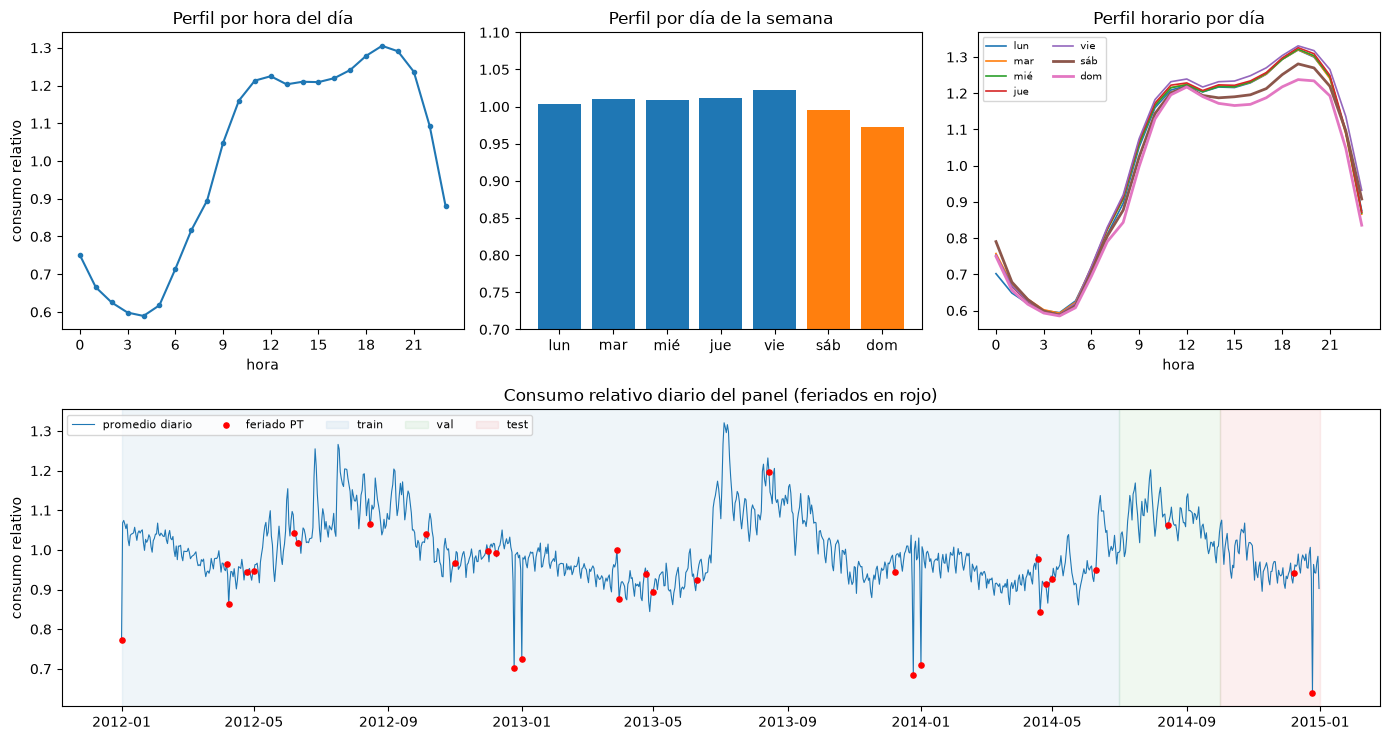

In [10]:
FERIADOS = holidays.Portugal(years=range(2011, 2016))
es_feriado = np.array([t.date() in FERIADOS for t in TIEMPOS])

rel = panel / panel.iloc[:T_VAL].mean()
rel_prom = rel.mean(axis=1)                         # perfil relativo promedio del panel
prof_hora = rel_prom.groupby(TIEMPOS.hour).mean()
dias_sem = ['lun', 'mar', 'mié', 'jue', 'vie', 'sáb', 'dom']
prof_sem = rel_prom.groupby(TIEMPOS.dayofweek).mean()
prof_hora_sem = rel_prom.groupby([TIEMPOS.dayofweek, TIEMPOS.hour]).mean().unstack(0)
diario = rel_prom.resample('D').mean()

fig = plt.figure(figsize=(14, 7.5))
ax1 = plt.subplot2grid((2, 3), (0, 0)); ax2 = plt.subplot2grid((2, 3), (0, 1)); ax3 = plt.subplot2grid((2, 3), (0, 2))
ax4 = plt.subplot2grid((2, 3), (1, 0), colspan=3)
ax1.plot(prof_hora.index, prof_hora.values, marker='o', ms=3)
ax1.set(title='Perfil por hora del día', xlabel='hora', ylabel='consumo relativo', xticks=range(0, 24, 3))
ax2.bar(dias_sem, prof_sem.values, color=['C0'] * 5 + ['C1'] * 2)
ax2.set(title='Perfil por día de la semana', ylim=(0.7, 1.1))
for j, d in enumerate(dias_sem):
    ax3.plot(prof_hora_sem.index, prof_hora_sem[j], label=d, lw=1.2 if j < 5 else 2)
ax3.set(title='Perfil horario por día', xlabel='hora', xticks=range(0, 24, 3)); ax3.legend(fontsize=7, ncol=2)
ax4.plot(diario.index, diario.values, lw=0.8, label='promedio diario')
fer_d = [pd.Timestamp(d) for d in FERIADOS if pd.Timestamp(INICIO) <= pd.Timestamp(d) <= pd.Timestamp(FIN)]
ax4.scatter(fer_d, diario.loc[fer_d].values, color='red', s=14, zorder=3, label='feriado PT')
for a, b, c, lab in [(INICIO, '2014-07-01', 'C0', 'train'), ('2014-07-01', '2014-10-01', 'C2', 'val'),
                     ('2014-10-01', FIN, 'C3', 'test')]:
    ax4.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=c, alpha=0.07, label=lab)
ax4.set(title='Consumo relativo diario del panel (feriados en rojo)', ylabel='consumo relativo'); ax4.legend(ncol=5, fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(REPORTS, 'perfiles_consumo.png'), dpi=130); plt.show()

**Navidad y Año Nuevo.** Se compara el consumo de cada día festivo contra el promedio del mismo día de la semana
en las 3 semanas previas (misma hora del año, sin efecto de estacionalidad semanal).

año      2012   2013   2014
día                        
24-dic  0.914  0.929  0.966
25-dic  0.689  0.693  0.665
31-dic  0.971  0.981  0.945
1-ene   0.796  0.797    NaN


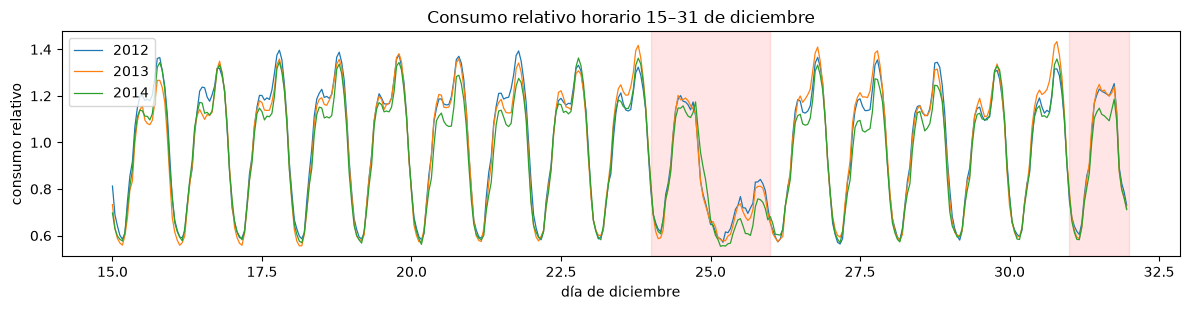

In [11]:
filas = []
for anio in (2012, 2013, 2014):
    for nombre, fecha in [('24-dic', f'{anio}-12-24'), ('25-dic', f'{anio}-12-25'),
                          ('31-dic', f'{anio}-12-31'), ('1-ene', f'{anio + 1}-01-01')]:
        f = pd.Timestamp(fecha)
        if f > pd.Timestamp(FIN):
            continue
        ref = diario.loc[[f - pd.Timedelta(weeks=k) for k in (1, 2, 3)]].mean()
        filas.append({'año': anio, 'día': nombre, 'día_sem': dias_sem[f.dayofweek],
                      'relativo_vs_3_semanas': round(diario.loc[f] / ref, 3)})
tabla_navidad = pd.DataFrame(filas).pivot(index='día', columns='año', values='relativo_vs_3_semanas')
print(tabla_navidad.loc[['24-dic', '25-dic', '31-dic', '1-ene']])

fig, ax = plt.subplots(figsize=(12, 3.2))
for anio in (2012, 2013, 2014):
    s = rel_prom.loc[f'{anio}-12-15':f'{anio}-12-31 23:00']
    ax.plot(np.arange(len(s)) / 24 + 15, s.values, lw=0.9, label=str(anio))
ax.axvspan(24, 26, color='red', alpha=0.1); ax.axvspan(31, 32, color='red', alpha=0.1)
ax.set(title='Consumo relativo horario 15–31 de diciembre', xlabel='día de diciembre', ylabel='consumo relativo')
ax.legend(); plt.tight_layout(); plt.savefig(os.path.join(REPORTS, 'navidad.png'), dpi=130); plt.show()

### 2.3 Escalas entre clientes y normalización

consumo promedio por cliente (kWh/h) en entrenamiento:
count      100.00
mean       529.44
std       1394.00
min         20.86
25%         84.15
50%        159.50
75%        318.33
max      11479.64

razón máximo / mínimo: 550×


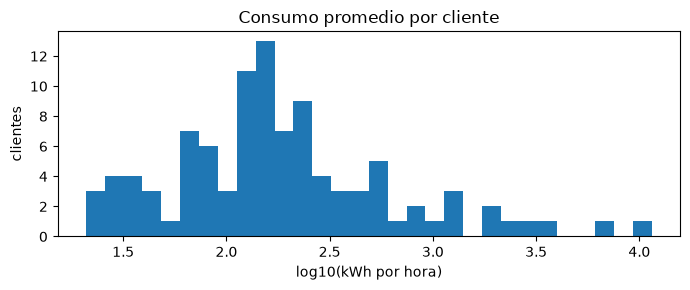

In [12]:
media_cli = panel.iloc[:T_VAL].mean()
print('consumo promedio por cliente (kWh/h) en entrenamiento:')
print(media_cli.describe(percentiles=[0.25, 0.5, 0.75]).round(2).to_string())
print(f'\nrazón máximo / mínimo: {media_cli.max() / media_cli.min():,.0f}×')
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(np.log10(media_cli.values), bins=30)
ax.set(title='Consumo promedio por cliente', xlabel='log10(kWh por hora)', ylabel='clientes')
plt.tight_layout(); plt.savefig(os.path.join(REPORTS, 'escalas_clientes.png'), dpi=130); plt.show()

Las escalas difieren en **varios órdenes de magnitud**. Opciones:

- **Global** (un solo μ, σ para todo el panel): la pérdida MSE quedaría dominada por los clientes grandes y los
  pequeños serían prácticamente constantes ≈ 0 para la red. Descartada.
- **Por serie** (z-score con μᵢ, σᵢ calculados **solo con entrenamiento**): pone a todos los clientes en la misma
  escala, permite un modelo **global** y no filtra información de validación/prueba. **Es la elegida por defecto.**
- **Por ventana** (RevIN: μ, σ de la ventana de entrada, que se revierten a la salida): se adapta a cambios de nivel
  recientes (p. ej. un cliente que cambia su consumo en 2014). Se implementa como opción (`norm='ventana'`) y se
  puede combinar con la anterior; es una de las iteraciones a explorar en 5.2.

In [13]:
MU = Y[:, :T_VAL].mean(axis=1, keepdims=True)           # (N, 1) — solo entrenamiento
SD = Y[:, :T_VAL].std(axis=1, keepdims=True) + 1e-6
Yn = ((Y - MU) / SD).astype(np.float32)                  # serie normalizada (N, T)

# Escala del MASE: MAE del seasonal naive de 24 h dentro de entrenamiento (por cliente).
M_MASE = 24
ESCALA_MASE = np.abs(Y[:, M_MASE:T_VAL] - Y[:, :T_VAL - M_MASE]).mean(axis=1)   # (N,)
print('Yn train: media', Yn[:, :T_VAL].mean().round(4), '| std', Yn[:, :T_VAL].std().round(4))

Yn train: media 0.0 | std 1.0


### 2.4 Covariables de calendario conocidas a futuro

Se conocen con certeza para cualquier instante futuro, así que pueden entrar al decoder / a la cabeza de salida.

| Covariable | Codificación | Motivo |
|---|---|---|
| hora (0–23) | seno/coseno, periodo 24 | las 23:00 quedan cerca de las 00:00 (continuidad cíclica) con solo 2 columnas |
| día de la semana (0–6) | seno/coseno, periodo 7 + indicador fin de semana | el sáb/dom es un régimen distinto, no solo una fase |
| mes (1–12) | seno/coseno, periodo 12 | estacionalidad anual suave |
| feriado | binaria (0/1) | días con comportamiento de domingo |

One-hot hubiera usado 24 + 7 + 12 columnas; con modelos globales y 100 series los embeddings serían otra opción,
pero seno/coseno es compacto, no requiere parámetros y funciona igual en todos los modelos.

In [14]:
def calendario(tiempos):
    h, d, m = tiempos.hour.values, tiempos.dayofweek.values, tiempos.month.values
    fer = np.array([t.date() in FERIADOS for t in tiempos], dtype=np.float32)
    return np.stack([np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24),
                     np.sin(2 * np.pi * d / 7),  np.cos(2 * np.pi * d / 7), (d >= 5).astype(float),
                     np.sin(2 * np.pi * (m - 1) / 12), np.cos(2 * np.pi * (m - 1) / 12), fer],
                    axis=1).astype(np.float32)

COLS_CAL = ['hora_sin', 'hora_cos', 'dow_sin', 'dow_cos', 'finde', 'mes_sin', 'mes_cos', 'feriado']
CAL = calendario(TIEMPOS)               # (T, C): depende solo de la marca de tiempo
C = CAL.shape[1]
print(pd.DataFrame(CAL[idx('2014-12-24 22:00'):idx('2014-12-25 03:00')], columns=COLS_CAL,
                   index=TIEMPOS[idx('2014-12-24 22:00'):idx('2014-12-25 03:00')]).round(3))

                     hora_sin  hora_cos  dow_sin  dow_cos  finde  mes_sin  mes_cos  feriado
2014-12-24 22:00:00    -0.500     0.866    0.975   -0.223    0.0     -0.5    0.866      0.0
2014-12-24 23:00:00    -0.259     0.966    0.975   -0.223    0.0     -0.5    0.866      0.0
2014-12-25 00:00:00     0.000     1.000    0.434   -0.901    0.0     -0.5    0.866      1.0
2014-12-25 01:00:00     0.259     0.966    0.434   -0.901    0.0     -0.5    0.866      1.0
2014-12-25 02:00:00     0.500     0.866    0.434   -0.901    0.0     -0.5    0.866      1.0


### 2.5 `Dataset` de ventanas deslizantes

Cada muestra es un par (cliente *i*, origen *t₀*):
- **X**: `(L, 1 + C)` = consumo normalizado `Yn[i, t₀−L : t₀]` + calendario `CAL[t₀−L : t₀]`.
- **y**: `(H,)` = `Yn[i, t₀ : t₀+H]`.
- **X_fut**: `(H, C)` = calendario `CAL[t₀ : t₀+H]` (conocido a futuro, para decoders y cabezas multi-salida).

Un origen es válido para una partición si **todo** su objetivo `[t₀, t₀+H)` cae dentro de ella. Con `diario=True`
solo se usan orígenes a las 00:00 (los del protocolo day-ahead). `__getitems__` arma el batch completo con
indexación vectorizada (mucho más rápido que 512 llamadas a `__getitem__`).

In [15]:
class VentanasDataset(Dataset):
    def __init__(self, Yn, CAL, L, H, t_ini, t_fin, stride=1, diario=False, series=None, t_min=0):
        self.Yn, self.CAL = torch.as_tensor(Yn), torch.as_tensor(CAL)
        self.L, self.H = L, H
        series = np.arange(Yn.shape[0]) if series is None else np.asarray(series)
        # orígenes: objetivo dentro de [t_ini, t_fin) y entrada que no empiece antes de t_min
        t0s = np.arange(max(t_ini, t_min + L), t_fin - H + 1, stride)
        if diario:
            t0s = t0s[t0s % 24 == 0]          # la malla empieza a las 00:00, así que t % 24 == 0 ⇔ 00:00
        self.series, self.t0s = series, t0s
        self.ar_L = torch.arange(-L, 0); self.ar_H = torch.arange(0, H)

    def __len__(self):
        return len(self.series) * len(self.t0s)

    def _decodifica(self, k):
        k = torch.as_tensor(k)
        return torch.as_tensor(self.series)[k // len(self.t0s)], torch.as_tensor(self.t0s)[k % len(self.t0s)]

    def __getitems__(self, ks):
        s, t0 = self._decodifica(np.asarray(ks))
        ti, to = t0[:, None] + self.ar_L, t0[:, None] + self.ar_H
        X = torch.cat([self.Yn[s[:, None], ti].unsqueeze(-1), self.CAL[ti]], dim=-1)   # (B, L, 1+C)
        return X, self.Yn[s[:, None], to], self.CAL[to], s                               # y: (B, H)

    def __getitem__(self, k):
        X, y, Xf, s = self.__getitems__([k])
        return X[0], y[0], Xf[0], s[0]

def loader(ds, batch=512, muestras=None, shuffle=False, seed=SEED):
    """DataLoader que entrega batches ya armados. `muestras` limita las ventanas por época (muestreo sin reemplazo)."""
    g = torch.Generator().manual_seed(seed)
    sampler = RandomSampler(ds, num_samples=muestras, generator=g) if (shuffle or muestras) else None
    return DataLoader(ds, batch_size=batch, sampler=sampler, collate_fn=lambda b: b)

L = 168
ds_tr = VentanasDataset(Yn, CAL, L, H, 0, T_VAL)
ds_va = VentanasDataset(Yn, CAL, L, H, T_VAL, T_TEST)
ds_te = VentanasDataset(Yn, CAL, L, H, T_TEST, T)
X, y, Xf, s = next(iter(loader(ds_tr, batch=4, shuffle=True)))
print('X', tuple(X.shape), '| y', tuple(y.shape), '| X_fut', tuple(Xf.shape), '| serie', s.tolist())

conteo = pd.DataFrame({
    'orígenes por serie (stride 1 h)': [len(d.t0s) for d in (ds_tr, ds_va, ds_te)],
    'ventanas en el panel (100 clientes)': [len(d) for d in (ds_tr, ds_va, ds_te)],
    f'ventanas con los {len(completos)} completos': [len(d.t0s) * len(completos) for d in (ds_tr, ds_va, ds_te)],
    'orígenes diarios 00:00 por serie': [len(VentanasDataset(Yn, CAL, L, H, a, b, diario=True).t0s)
                                         for a, b in ((0, T_VAL), (T_VAL, T_TEST), (T_TEST, T))],
}, index=['entrenamiento', 'validación', 'prueba'])
print(f'L = {L}, H = {H}, stride = 1 h'); print(conteo.to_string())

X (4, 168, 9) | y (4, 24) | X_fut (4, 24, 8) | serie [41, 77, 96, 11]
L = 168, H = 24, stride = 1 h
               orígenes por serie (stride 1 h)  ventanas en el panel (100 clientes)  ventanas con los 314 completos  orígenes diarios 00:00 por serie
entrenamiento                            21697                              2169700                         6812858                               905
validación                                2185                               218500                          686090                                92
prueba                                    2185                               218500                          686090                                92


Las primeras L = 168 horas de entrenamiento no pueden ser origen (no tienen historia suficiente) y las últimas
H − 1 = 23 horas de cada partición tampoco (su objetivo se saldría). En prueba hay **2,185** orígenes con stride de
1 h, de los cuales **92** son a las 00:00: esos 92 son los que usa el backtest.

### 2.6 Auditoría de fugas

Regla: **cada entrada de la red debe poder calcularse en el instante en que se emite el pronóstico** (00:00 del día
objetivo, con datos hasta las 23:00 del día anterior). Las cuatro fugas vistas en clase y cómo las evita el pipeline:

In [16]:
# Fuga 1 — split aleatorio de ventanas: las particiones se cortan por fecha, no se barajan ventanas entre ellas.
fin_obj_tr = ds_tr.t0s.max() + H - 1           # última hora objetivo de entrenamiento
ini_obj_va, fin_obj_va = ds_va.t0s.min(), ds_va.t0s.max() + H - 1
ini_obj_te = ds_te.t0s.min()
assert fin_obj_tr < T_VAL <= ini_obj_va and fin_obj_va < T_TEST <= ini_obj_te
print('1) objetivos train ≤', TIEMPOS[fin_obj_tr], '< val desde', TIEMPOS[ini_obj_va],
      '| val ≤', TIEMPOS[fin_obj_va], '< test desde', TIEMPOS[ini_obj_te])
print('   el barajado (shuffle) ocurre solo DENTRO de ds_tr (RandomSampler sobre ese Dataset)')

# Fuga 2 — escalar con toda la serie: μ y σ salen solo de [0, T_VAL).
mu_toda, sd_toda = Y.mean(axis=1), Y.std(axis=1)
assert np.allclose(MU[:, 0], Y[:, :T_VAL].mean(axis=1)) and not np.allclose(MU[:, 0], mu_toda)
print(f'2) μ con train vs. con toda la serie: diferencia media {np.abs(MU[:, 0] - mu_toda).mean() / MU.mean():.2%} '
      f'del nivel → se usan solo estadísticos de train (igual para la escala del MASE)')

# Fuga 3 — early stopping con la prueba: la función de entrenamiento solo recibe ds_tr y ds_va;
# ds_te no se pasa a `entrenar` y la prueba solo se toca en backtest() una vez por modelo (sección 4).
print('3) early stopping monitorea la pérdida de VALIDACIÓN (jul–sep 2014); prueba solo en backtest()')

# Fuga 4 — covariables mal alineadas: la última hora de X es t0−1 y las covariables futuras son las de [t0, t0+H).
X1, y1, Xf1, _ = ds_te[0]                       # muestra 0 = cliente 0, origen T_TEST
assert torch.allclose(X1[-1, 0], torch.tensor(Yn[0, T_TEST - 1]))      # último valor visto: 23:00 del día anterior
assert torch.allclose(y1[0], torch.tensor(Yn[0, T_TEST]))              # primer objetivo: 00:00
assert torch.allclose(Xf1, torch.tensor(CAL[T_TEST:T_TEST + H]))       # calendario del día objetivo
assert torch.allclose(X1[:, 1:], torch.tensor(CAL[T_TEST - L:T_TEST]))  # calendario de la entrada = sus propias horas
print('4) origen', TIEMPOS[T_TEST], '| última entrada', TIEMPOS[T_TEST - 1], '| objetivo',
      TIEMPOS[T_TEST], '→', TIEMPOS[T_TEST + H - 1])
print('   X_fut solo contiene calendario (función de la fecha), nunca consumo futuro;')
print('   no se usan rezagos < 1 ni promedios móviles centrados. Las correcciones DST usan solo el mismo día.')

1) objetivos train ≤ 2014-06-30 23:00:00 < val desde 2014-07-01 00:00:00 | val ≤ 2014-09-30 23:00:00 < test desde 2014-10-01 00:00:00
   el barajado (shuffle) ocurre solo DENTRO de ds_tr (RandomSampler sobre ese Dataset)


2) μ con train vs. con toda la serie: diferencia media 0.99% del nivel → se usan solo estadísticos de train (igual para la escala del MASE)
3) early stopping monitorea la pérdida de VALIDACIÓN (jul–sep 2014); prueba solo en backtest()
4) origen 2014-10-01 00:00:00 | última entrada 2014-09-30 23:00:00 | objetivo 2014-10-01 00:00:00 → 2014-10-01 23:00:00
   X_fut solo contiene calendario (función de la fecha), nunca consumo futuro;
   no se usan rezagos < 1 ni promedios móviles centrados. Las correcciones DST usan solo el mismo día.


## 3. Investigación: herramientas para forecasting en PyTorch

### 3.1 `nn.LSTM` y `nn.GRU` [1]

Redes recurrentes que recorren la secuencia paso a paso manteniendo un estado oculto. La LSTM tiene además una
**celda de memoria** `c` controlada por compuertas de entrada, olvido y salida; la GRU fusiona compuertas (reset y
update), no tiene celda y usa ~25 % menos parámetros.

| Parámetro | Propósito |
|---|---|
| `input_size` | número de features por paso (aquí 1 + 8 covariables = 9) |
| `hidden_size` | dimensión del estado oculto *h* (capacidad del modelo) |
| `num_layers` | capas recurrentes apiladas (la salida de una es la entrada de la siguiente) |
| `batch_first` | si `True`, tensores `(batch, seq, feature)` en vez de `(seq, batch, feature)` |
| `dropout` | dropout entre capas apiladas (no aplica a la última; requiere `num_layers > 1`) |

Salidas con `batch_first=True`: `output (B, L, D·hidden)` = estado oculto de la **última capa en cada paso**;
`h_n (D·num_layers, B, hidden)` = estado oculto **final de cada capa**; `c_n` (solo LSTM, misma forma que `h_n`) =
celda final de cada capa. `D = 2` si `bidirectional=True` (no se usa en forecasting causal). Para multi-salida se usa
`h_n[-1]` (o `output[:, -1]`, equivalente); para un encoder–decoder `(h_n, c_n)` inicializa el decoder.

### 3.2 `nn.Conv1d` con *dilation* y padding causal: TCN [2]

`nn.Conv1d(in_channels, out_channels, kernel_size, dilation, padding)` aplica filtros 1-D sobre el tiempo con entrada
`(B, canales, L)`. Con `dilation = d` el filtro toma muestras separadas `d` pasos. **Padding causal**: se rellenan
`(k−1)·d` ceros **solo a la izquierda** (`F.pad(x, ((k-1)*d, 0))` o padding simétrico y recortar la cola) para que la
salida en *t* dependa solo de *t, t−1, …* (nunca del futuro). Una TCN apila bloques residuales con
`d = 1, 2, 4, …, 2^(n−1)`; su **campo receptivo** es
`R = 1 + Σᵢ (k − 1)·dᵢ` (por cada convolución del bloque; con 2 convoluciones por bloque se multiplica por 2).
Ej.: k = 3 y d = 1…64 (7 niveles, 1 conv) → R = 1 + 2·127 = 255 h ≥ una semana.

### 3.3 `nn.TransformerEncoderLayer` y codificación posicional [1][3]

Bloque de **auto-atención multi-cabeza + red feed-forward**, cada una con residual y LayerNorm.
`d_model` = dimensión de los embeddings (debe ser divisible entre `nhead`); `nhead` = cabezas de atención, cada una de
dimensión `d_model / nhead`; `dim_feedforward` = ancho de la capa oculta del MLP (típicamente 2–4 × `d_model`);
además `dropout`, `batch_first`, `norm_first`. Se apila con `nn.TransformerEncoder(layer, num_layers)`.
La atención es invariante a permutaciones, así que el orden se inyecta **sumando** una codificación posicional al
embedding de entrada: sinusoidal fija `PE(t, 2i) = sin(t / 10000^{2i/d})`, `PE(t, 2i+1) = cos(·)` o una
`nn.Parameter` aprendida `(L, d_model)`. En series de tiempo también se suman las covariables de calendario
proyectadas, y PatchTST [4] agrupa la serie en *patches* (p. ej. 16 h) que actúan como tokens.

### 3.4 NeuralForecast y StatsForecast (Nixtla) [5][6]

Ambas reciben un **DataFrame largo** con columnas `unique_id` (id de la serie), `ds` (marca de tiempo) e `y`
(valor); las covariables futuras van como columnas extra y se declaran con `futr_exog_list`. Se instancian con una
lista de modelos y la frecuencia: `StatsForecast(models=[...], freq='h', n_jobs=-1)` /
`NeuralForecast(models=[NHITS(h=24, input_size=168, ...)], freq='h')`.

`cross_validation(df, h, n_windows, step_size, refit)` hace backtesting con origen móvil:
- `n_windows`: número de orígenes (aquí 92);
- `step_size`: separación entre orígenes consecutivos (24 h → un pronóstico por día);
- `refit`: `False` entrena una sola vez en el primer corte y luego solo predice con la historia nueva (protocolo de
  este lab); `True` reentrena en cada ventana; un entero *k* reentrena cada *k* ventanas (útil para el reentrenamiento
  mensual). En NeuralForecast además están `val_size`/`test_size`.
Devuelve `unique_id, ds, cutoff, y` y una columna por modelo, listo para calcular métricas.

### 3.5 `BaseChronosPipeline.predict_quantiles` (Chronos) [7]

Chronos es un modelo fundacional preentrenado (Chronos-Bolt: encoder–decoder T5 que predice cuantiles directamente).
`BaseChronosPipeline.from_pretrained('amazon/chronos-bolt-small')` carga el modelo y
`predict_quantiles(context, prediction_length=24, quantile_levels=[0.1, 0.5, 0.9])` recibe `context` como tensor
1-D o `(batch, longitud)` (o lista de tensores de distinto largo) con la **historia cruda** (escala interna propia) y
devuelve `(quantiles (B, H, Q), mean (B, H))`. Es **zero-shot**: no se entrena.

### 3.6 Conceptos

- **Modelo local vs. global.** Local = un modelo por serie (ARIMA/ETS clásicos): se adapta a cada cliente pero cada uno
  aprende de ~22 k puntos y no transfiere patrones. Global = un solo modelo para todas las series (normalizadas): ve
  100× más datos, comparte patrones (hora, día, feriados) y generaliza a series nuevas; es lo que hace funcionar al
  deep learning en forecasting [8].
- **Teacher forcing.** Al entrenar un modelo autorregresivo / seq2seq, en cada paso del decoder se alimenta el
  **valor real** anterior en lugar de la predicción. Acelera y estabiliza el entrenamiento, pero en inferencia el
  modelo ve sus propios errores (*exposure bias*); se mitiga con *scheduled sampling* (alimentar la predicción con
  probabilidad creciente).
- **RevIN** [9]. Normaliza cada ventana de entrada con su propia media y desviación (más un afín aprendible), pasa la
  ventana normalizada a la red y **revierte** la transformación en la salida. Ante un cambio de nivel (el cliente
  consume 30 % más en 2014 que en 2012) la red ve siempre una ventana centrada, así que no extrapola fuera del rango
  de entrenamiento.
- **Pinball loss.** Para un cuantil τ: `ρ_τ(y, ŷ) = max(τ·(y − ŷ), (τ − 1)·(y − ŷ))`. Penaliza la sub-predicción con
  peso τ y la sobre-predicción con 1 − τ; su minimizador es el **cuantil τ** de la distribución condicional
  (τ = 0.5 → mediana, equivale a MAE/2). Promediada sobre varios τ aproxima el CRPS.
- **MASE vs. WAPE.** MASE = MAE del modelo / MAE del seasonal naive *dentro de entrenamiento*: < 1 significa mejor que
  repetir el día anterior y se promedia por serie (cada cliente pesa igual). WAPE = Σ|error| / Σ|real| sobre todo el
  panel: es un % del volumen total, por lo que pesa más a los clientes grandes. Ambos son libres de escala, pero
  ninguno explota con valores reales ≈ 0 (a diferencia del MAPE).

**Referencias**
[1] PyTorch docs — `torch.nn` (LSTM, GRU, Conv1d, TransformerEncoderLayer). ·
[2] Bai, Kolter & Koltun (2018), *An Empirical Evaluation of Generic Convolutional and Recurrent Networks for Sequence Modeling*. ·
[3] Vaswani et al. (2017), *Attention Is All You Need*. ·
[4] Nie et al. (2023), *A Time Series is Worth 64 Words* (PatchTST). ·
[5] Nixtla, *StatsForecast* docs. · [6] Nixtla, *NeuralForecast* docs. ·
[7] Ansari et al. (2024), *Chronos: Learning the Language of Time Series*; repo `amazon-science/chronos-forecasting`. ·
[8] Montero-Manso & Hyndman (2021), *Principles and algorithms for forecasting groups of time series: locality and globality*. ·
[9] Kim et al. (2022), *Reversible Instance Normalization for Accurate Time-Series Forecasting against Distribution Shift*. ·
[10] Zeng et al. (2023), *Are Transformers Effective for Time Series Forecasting?* (DLinear/NLinear).

## 4. Protocolo de validación y métricas

Una sola función `backtest(modelo)` evalúa **todos** los modelos. El modelo solo tiene que exponer
`predecir(hist, t0) → (N, 24)` en kWh, donde `hist = Y[:, :t0]` es una **copia de solo lectura** con los datos hasta
las 23:00 del día anterior: el modelo físicamente no puede ver el futuro. Si además devuelve cuantiles
`(N, 24, 3)` para P10/P50/P90, se guardan para las métricas probabilísticas.

Para modelos de librería (StatsForecast, NeuralForecast, LightGBM, Chronos) cuyo `cross_validation` ya produce los
92 pronósticos, `PronosticosPrecalculados` los adapta a la misma interfaz y `backtest` verifica que el `cutoff` de
cada pronóstico sea exactamente el origen (23:00 del día anterior).

In [17]:
N_ORIGENES = (T - T_TEST) // 24          # 92
ORIGENES = T_TEST + 24 * np.arange(N_ORIGENES)
Y_RO = Y.copy(); Y_RO.flags.writeable = False
assert N_ORIGENES == 92

def backtest(modelo, origenes=ORIGENES, H=H):
    """Backtesting con origen móvil diario. Devuelve un DataFrame largo con y, y_hat (y cuantiles si existen)."""
    preds, cuant = [], []
    t_ini = time.perf_counter()
    for t0 in origenes:
        out = modelo.predecir(Y_RO[:, :t0], int(t0))
        if isinstance(out, tuple):
            out, q = out; cuant.append(np.asarray(q))
        out = np.asarray(out, dtype=np.float64)
        assert out.shape == (N, H), f'{modelo.nombre}: forma {out.shape}'
        preds.append(out)
    t_inf = time.perf_counter() - t_ini
    P = np.stack(preds, axis=1)                                   # (N, O, H)
    tt = np.asarray(origenes)[:, None] + np.arange(H)             # (O, H) índices de tiempo
    res = pd.DataFrame({
        'unique_id': np.repeat(CLIENTES, len(origenes) * H),
        'ds': np.tile(TIEMPOS[tt.ravel()], N),
        'origen': np.tile(np.repeat(TIEMPOS[np.asarray(origenes) - 1], H), N),   # cutoff = 23:00 del día anterior
        'h': np.tile(np.arange(1, H + 1), N * len(origenes)),
        'y': Y[:, tt].ravel(),
        'y_hat': P.ravel()})
    if cuant:
        Q = np.stack(cuant, axis=1)                               # (N, O, H, 3)
        for j, nom in enumerate(['p10', 'p50', 'p90']):
            res[nom] = Q[..., j].ravel()
    res['modelo'] = modelo.nombre
    res.attrs['t_inferencia_s'] = t_inf
    return res

class PronosticosPrecalculados:
    """Adapta la salida de `cross_validation` (unique_id, ds, cutoff, <col>) a la interfaz de backtest."""
    def __init__(self, df, col, nombre=None, cuantiles=None):
        self.nombre = nombre or col
        df = df.copy(); df['ds'] = pd.to_datetime(df['ds']); df['cutoff'] = pd.to_datetime(df['cutoff'])
        cols = [col] + (list(cuantiles) if cuantiles else [])
        self.tab = df.pivot_table(index=['cutoff', 'ds'], columns='unique_id', values=cols)
        self.col, self.cuantiles = col, cuantiles

    def predecir(self, hist, t0):
        corte = TIEMPOS[t0 - 1]
        assert hist.shape[1] == t0
        bloque = self.tab.loc[corte]                               # falla si no existe un pronóstico con ese cutoff
        assert (bloque.index == TIEMPOS[t0:t0 + H]).all(), 'pronóstico desalineado con el origen'
        yhat = bloque[self.col][CLIENTES].values.T                 # (N, H)
        if self.cuantiles:
            q = np.stack([bloque[c][CLIENTES].values.T for c in self.cuantiles], axis=-1)
            return yhat, q
        return yhat

**Métricas** (en kWh, agregadas sobre todos los clientes y orígenes):

- **MAE**, **RMSE**; también por cliente.
- **WAPE** = Σ|error| / Σ|real| sobre todo el panel.
- **MAPE** = promedio de |error| / |real| (sobre horas con real > 0). Con clientes de consumo ≈ 0 el denominador
  minúsculo hace que un error de pocos kWh valga cientos de %, así que el MAPE lo dominan esos clientes.
- **MASE** = MAEᵢ / escalaᵢ por cliente, con escalaᵢ = MAE del seasonal naive de 24 h en entrenamiento; se promedia
  sobre clientes.
- Probabilísticas: **pinball loss** promedio en P10/P50/P90 (normalizada por la escala MASE para ser comparable) y
  **cobertura** P10–P90 (ideal: 80 %).

In [18]:
ESCALA = pd.Series(ESCALA_MASE, index=CLIENTES)
NAVIDAD = ('2014-12-22 00:00', '2014-12-28 23:00')

def _mase(df):
    mae_i = (df['y'] - df['y_hat']).abs().groupby(df['unique_id']).mean()
    return float((mae_i / ESCALA.loc[mae_i.index]).mean())

def metricas(res):
    e = res['y_hat'] - res['y']
    pos = res['y'] > 0
    m = {'MAE': e.abs().mean(), 'RMSE': np.sqrt((e ** 2).mean()),
         'WAPE': e.abs().sum() / res['y'].abs().sum(),
         'MAPE': (e[pos].abs() / res['y'][pos]).mean(),
         'MASE': _mase(res)}
    nav = res[(res['ds'] >= NAVIDAD[0]) & (res['ds'] <= NAVIDAD[1])]
    m['MASE_navidad'] = _mase(nav)
    if 'p10' in res:
        tau = {'p10': 0.1, 'p50': 0.5, 'p90': 0.9}
        pin = np.mean([np.maximum(t * (res['y'] - res[c]), (t - 1) * (res['y'] - res[c])) /
                       ESCALA.loc[res['unique_id']].values for c, t in tau.items()], axis=0)
        m['pinball_esc'] = float(pin.mean())
        m['cobertura_80'] = float(((res['y'] >= res['p10']) & (res['y'] <= res['p90'])).mean())
    return m

def metricas_por_cliente(res):
    g = res.assign(ae=(res['y_hat'] - res['y']).abs(), se=(res['y_hat'] - res['y']) ** 2).groupby('unique_id')
    out = pd.DataFrame({'MAE': g['ae'].mean(), 'RMSE': np.sqrt(g['se'].mean()), 'media_y': g['y'].mean()})
    out['MASE'] = out['MAE'] / ESCALA.loc[out.index]
    return out

def error_por_paso(res):
    return (res['y_hat'] - res['y']).abs().groupby(res['h']).mean()          # MAE por h = 1…24

def error_por_hora(res):
    return (res['y_hat'] - res['y']).abs().groupby(res['ds'].dt.hour).mean()  # MAE por hora del día

RESULTADOS, METRICAS, INFO = {}, {}, {}    # resultados de backtest, métricas y metadatos por modelo

def registrar(res, **info):
    """Guarda el backtest de un modelo y sus métricas (la prueba se usa una sola vez por modelo)."""
    nom = res['modelo'].iat[0]
    RESULTADOS[nom] = res
    METRICAS[nom] = metricas(res)
    INFO[nom] = dict(info, t_inferencia_s=res.attrs.get('t_inferencia_s', np.nan))
    print(f"{nom:<22} MAE {METRICAS[nom]['MAE']:8.3f}  RMSE {METRICAS[nom]['RMSE']:8.3f}  "
          f"WAPE {METRICAS[nom]['WAPE']:.4f}  MAPE {METRICAS[nom]['MAPE']:.3f}  MASE {METRICAS[nom]['MASE']:.4f}  "
          f"MASE nav. {METRICAS[nom]['MASE_navidad']:.4f}")

## 5. Construcción y entrenamiento de los modelos

### 5.0 Baselines (StatsForecast)

Naive (repite la última hora), seasonal naive de 24 h (repite el día anterior) y de 168 h (repite el mismo día de la
semana pasada), y **MSTL** (descomposición con estacionalidades de 24 y 168 h + AutoETS sobre la tendencia).
Naive y seasonal naive usan `cross_validation(h=24, step_size=24, n_windows=92, refit=False)`: no tienen pesos, en cada
origen solo leen la historia hasta las 23:00 del día anterior. MSTL es un modelo **local** (una descomposición por
cliente): se reajusta en cada origen con las últimas 4 semanas (`input_size=672`, `refit=True`), que es su forma
natural de operar y sigue usando solo datos anteriores al origen. Cuesta ~0.07 s por ajuste × 9,200 ajustes,
así que se paraleliza con `n_jobs=-1`.

In [19]:
from statsforecast import StatsForecast
from statsforecast.models import Naive, SeasonalNaive, MSTL, AutoETS

DF_LARGO = (panel.rename_axis('ds').reset_index()
            .melt(id_vars='ds', var_name='unique_id', value_name='y')[['unique_id', 'ds', 'y']])
CV_CACHE = os.path.join(DATA, 'cv_statsforecast.parquet')
if os.path.exists(CV_CACHE) and not RETRAIN:
    cv_sf = pd.read_parquet(CV_CACHE); t_sf = json.load(open(CV_CACHE + '.json'))
else:
    t_sf = {}
    modelos_sf = [Naive(), SeasonalNaive(24, alias='SeasonalNaive24'), SeasonalNaive(168, alias='SeasonalNaive168')]
    sf = StatsForecast(models=modelos_sf, freq='h', n_jobs=-1)
    t = time.perf_counter()
    cv_sf = sf.cross_validation(df=DF_LARGO, h=H, step_size=24, n_windows=N_ORIGENES, refit=False)
    t_sf['simples'] = time.perf_counter() - t
    # MSTL: se reajusta en cada origen con las últimas 4 semanas (input_size) para que el ajuste sea barato.
    sf_mstl = StatsForecast(models=[MSTL(season_length=[24, 168], trend_forecaster=AutoETS(model='ZZN'),
                                         alias='MSTL')], freq='h', n_jobs=-1)
    t = time.perf_counter()
    cv_m = sf_mstl.cross_validation(df=DF_LARGO, h=H, step_size=24, n_windows=N_ORIGENES, refit=True,
                                    input_size=24 * 7 * 4)
    t_sf['MSTL'] = time.perf_counter() - t
    cv_sf = cv_sf.merge(cv_m[['unique_id', 'ds', 'cutoff', 'MSTL']], on=['unique_id', 'ds', 'cutoff'])
    cv_sf.to_parquet(CV_CACHE); json.dump(t_sf, open(CV_CACHE + '.json', 'w'))
print('tiempos StatsForecast (s):', {k: round(v, 1) for k, v in t_sf.items()})

for col, L_eq in [('Naive', 1), ('SeasonalNaive24', 24), ('SeasonalNaive168', 168), ('MSTL', 24 * 7 * 4)]:
    res = backtest(PronosticosPrecalculados(cv_sf, col))
    t_fit = t_sf['MSTL'] if col == 'MSTL' else t_sf['simples'] / 3
    registrar(res, familia='Baseline', L=L_eq, estrategia='—', covariables=False, params=0, params_entrenables=0,
              t_entrenamiento_s=t_fit, hardware='CPU (StatsForecast)')

tiempos StatsForecast (s): {'simples': 1.1, 'MSTL': 122.4}
Naive                  MAE  158.588  RMSE  504.684  WAPE 0.3077  MAPE 0.400  MASE 3.9891  MASE nav. 3.9055


SeasonalNaive24        MAE   44.128  RMSE  232.232  WAPE 0.0856  MAPE 0.118  MASE 1.0341  MASE nav. 2.1679
SeasonalNaive168       MAE   39.721  RMSE  182.448  WAPE 0.0771  MAPE 0.112  MASE 1.1137  MASE nav. 1.6018


MSTL                   MAE   36.034  RMSE  182.711  WAPE 0.0699  MAPE 0.104  MASE 0.9373  MASE nav. 1.9695


### 5.1 Modelos propios en PyTorch

Todos son **globales** (un modelo para los 100 clientes), trabajan sobre la serie normalizada por cliente y
comparten la firma `forward(X, X_fut) → (B, 24)`:

| Modelo | Entrada | Estrategia multi-paso | Covariables |
|---|---|---|---|
| **MLP** | últimas L horas + calendario futuro aplanado | multi-salida | sí (futuras) |
| **DLinear** [10] | últimas L horas, descompuestas en tendencia (media móvil k = 25) + estacional, una capa lineal L→H por componente | multi-salida | no |
| **NLinear** [10] | últimas L horas menos el último valor; lineal L→H; se suma el último valor | multi-salida | no |
| **LSTM multi-salida** | X `(L, 9)` → LSTM → `h_n` + calendario futuro → lineal → 24 | multi-salida | sí |
| **LSTM autorregresiva** | un paso: `[y_t, cal_{t+1}] → ŷ_{t+1}`; se realimenta 24 veces | recursiva | sí |
| **Seq2seq (LSTM)** | encoder LSTM sobre X; decoder LSTM con `[ŷ_{t−1}, cal_t]` inicializado con `(h_n, c_n)` | encoder–decoder | sí (en el decoder) |

`ConRevIN` envuelve cualquiera de ellos para la normalización **por ventana** (opción `norm='ventana'`).

In [20]:
class MLP(nn.Module):
    def __init__(self, L, H=24, C=8, oculto=512, dropout=0.1):
        super().__init__()
        self.red = nn.Sequential(nn.Linear(L + H * C, oculto), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(oculto, oculto // 2), nn.ReLU(), nn.Linear(oculto // 2, H))
    def forward(self, X, Xf):
        return self.red(torch.cat([X[:, :, 0], Xf.flatten(1)], dim=1))

class DLinear(nn.Module):
    def __init__(self, L, H=24, k=25):
        super().__init__()
        self.k = k
        self.lin_est, self.lin_ten = nn.Linear(L, H), nn.Linear(L, H)
    def forward(self, X, Xf=None):
        x = X[:, :, 0]
        # media móvil con relleno replicado en ambos extremos de la VENTANA (no usa datos fuera de ella)
        xp = torch.cat([x[:, :1].repeat(1, (self.k - 1) // 2), x, x[:, -1:].repeat(1, self.k // 2)], dim=1)
        tendencia = F.avg_pool1d(xp.unsqueeze(1), self.k, stride=1).squeeze(1)
        return self.lin_est(x - tendencia) + self.lin_ten(tendencia)

class NLinear(nn.Module):
    def __init__(self, L, H=24):
        super().__init__()
        self.lin = nn.Linear(L, H)
    def forward(self, X, Xf=None):
        x = X[:, :, 0]; ultimo = x[:, -1:]
        return self.lin(x - ultimo) + ultimo

class LSTMMultiSalida(nn.Module):
    def __init__(self, C=8, H=24, oculto=64, capas=2, dropout=0.1):
        super().__init__()
        self.lstm = nn.LSTM(1 + C, oculto, capas, batch_first=True, dropout=dropout if capas > 1 else 0)
        self.cabeza = nn.Linear(oculto + H * C, H)
    def forward(self, X, Xf):
        _, (h_n, _) = self.lstm(X)
        return self.cabeza(torch.cat([h_n[-1], Xf.flatten(1)], dim=1))

class LSTMAutorregresiva(nn.Module):
    """Modelo de un paso. Entrena con teacher forcing sobre la secuencia [t0−L, t0+H); predice recursivamente."""
    def __init__(self, C=8, oculto=64, capas=2, dropout=0.1):
        super().__init__()
        self.lstm = nn.LSTM(1 + C, oculto, capas, batch_first=True, dropout=dropout if capas > 1 else 0)
        self.salida = nn.Linear(oculto, 1)
    def perdida(self, X, y, Xf, fn):
        yfull = torch.cat([X[:, :, 0], y], dim=1)                 # (B, L+H): valores reales (teacher forcing)
        calfull = torch.cat([X[:, :, 1:], Xf], dim=1)             # (B, L+H, C)
        z = torch.cat([yfull[:, :-1, None], calfull[:, 1:]], dim=-1)   # entrada en t: [y_t, cal_{t+1}]
        out, _ = self.lstm(z)
        return fn(self.salida(out).squeeze(-1), yfull[:, 1:])      # objetivo: y_{t+1} (un paso)
    def forward(self, X, Xf):
        calfull = torch.cat([X[:, :, 1:], Xf], dim=1)
        z = torch.cat([X[:, :, :1], calfull[:, 1:X.shape[1] + 1]], dim=-1)
        out, estado = self.lstm(z)
        y_t = self.salida(out[:, -1])                              # ŷ_{t0}
        preds = [y_t]
        for h in range(1, Xf.shape[1]):                            # realimenta su propia predicción
            out, estado = self.lstm(torch.cat([y_t, Xf[:, h]], dim=-1).unsqueeze(1), estado)
            y_t = self.salida(out[:, -1]); preds.append(y_t)
        return torch.cat(preds, dim=1)

class Seq2Seq(nn.Module):
    """Encoder LSTM + decoder LSTM con covariables de calendario del día objetivo."""
    def __init__(self, C=8, oculto=64, capas=2, dropout=0.1, p_teacher=0.5):
        super().__init__()
        d = dropout if capas > 1 else 0
        self.enc = nn.LSTM(1 + C, oculto, capas, batch_first=True, dropout=d)
        self.dec = nn.LSTM(1 + C, oculto, capas, batch_first=True, dropout=d)
        self.salida = nn.Linear(oculto, 1)
        self.p_teacher = p_teacher
    def _decodifica(self, X, Xf, y=None):
        _, estado = self.enc(X)
        y_prev = X[:, -1, :1]                                      # último valor observado (23:00)
        preds = []
        for h in range(Xf.shape[1]):
            out, estado = self.dec(torch.cat([y_prev, Xf[:, h]], dim=-1).unsqueeze(1), estado)
            y_h = self.salida(out[:, -1]); preds.append(y_h)
            usar_real = y is not None and torch.rand(()) < self.p_teacher
            y_prev = y[:, h:h + 1] if usar_real else y_h           # teacher forcing con probabilidad p_teacher
        return torch.cat(preds, dim=1)
    def perdida(self, X, y, Xf, fn):
        return fn(self._decodifica(X, Xf, y), y)
    def forward(self, X, Xf):
        return self._decodifica(X, Xf)

class ConRevIN(nn.Module):
    """Normalización por ventana (RevIN): normaliza el canal de consumo con μ, σ de la entrada y revierte a la salida."""
    def __init__(self, base, eps=1e-5):
        super().__init__()
        self.base, self.eps = base, eps
        self.gamma, self.beta = nn.Parameter(torch.ones(1)), nn.Parameter(torch.zeros(1))
    def _norm(self, X):
        m = X[:, :, :1].mean(1, keepdim=True); s = X[:, :, :1].std(1, keepdim=True) + self.eps
        Xn = torch.cat([(X[:, :, :1] - m) / s * self.gamma + self.beta, X[:, :, 1:]], dim=-1)
        return Xn, m[:, :, 0], s[:, :, 0]
    def _desnorm(self, o, m, s):
        return (o - self.beta) / self.gamma * s + m
    def forward(self, X, Xf):
        Xn, m, s = self._norm(X)
        return self._desnorm(self.base(Xn, Xf), m, s)
    def perdida(self, X, y, Xf, fn):
        if hasattr(self.base, 'perdida'):          # entrena en la escala de la ventana
            Xn, m, s = self._norm(X)
            return self.base.perdida(Xn, (y - m) / s * self.gamma + self.beta, Xf, fn)
        return fn(self.forward(X, Xf), y)

### 5.2 Entrenamiento con registro de iteraciones

`entrenar(nombre, construir, cfg)` entrena **solo con `ds_tr` y `ds_va`** y registra todo lo que pide el enunciado:
configuración (L, H, meses de historia, normalización, tamaño oculto, capas, dropout, lr, batch), pérdida de
entrenamiento y validación por época, **MAE y MASE de validación al final de cada época** (en kWh, sobre los 92
orígenes diarios de jul–sep), parámetros totales/entrenables, tiempo por época y total, y memoria pico de GPU.
Cada época usa una muestra aleatoria de `muestras` ventanas de entrenamiento (de ~2.2 M posibles con stride 1 h).
**Early stopping** con paciencia sobre la pérdida de validación; se restauran los mejores pesos.
Los pesos y el historial se guardan en `data/modelos/` y se reutilizan al re-ejecutar.

In [21]:
CFG_BASE = dict(L=168, H=24, meses=None, norm='serie', lr=1e-3, batch=512, muestras=100_000,
                epocas=40, paciencia=5, perdida='mae', weight_decay=0.0, seed=SEED)
if QUICK:
    CFG_BASE.update(muestras=4_000, epocas=2)
ITERACIONES = []        # una fila por entrenamiento (para la tabla de iteraciones de 5.2)
HISTORIALES = {}        # curvas por época

def _sync():
    if DEVICE.type == 'mps': torch.mps.synchronize()
    elif DEVICE.type == 'cuda': torch.cuda.synchronize()

def _mem_gpu():
    if DEVICE.type == 'mps': return torch.mps.driver_allocated_memory() / 2**20
    if DEVICE.type == 'cuda': return torch.cuda.max_memory_allocated() / 2**20
    return float('nan')

def contar_parametros(m):
    return sum(p.numel() for p in m.parameters()), sum(p.numel() for p in m.parameters() if p.requires_grad)

def ds_entrenamiento(cfg):
    """Ventanas de entrenamiento; con `meses` solo se usa la historia más reciente antes de 2014-07-01."""
    t_val = cfg.get('t_val', T_VAL)
    t_min = 0 if cfg['meses'] is None else max(0, idx(TIEMPOS[t_val] - pd.DateOffset(months=cfg['meses'])))
    return VentanasDataset(Yn, CAL, cfg['L'], cfg['H'], 0, t_val, t_min=t_min, series=cfg.get('series'))

@torch.no_grad()
def evaluar_val(modelo, ds_va, fn):
    """Pérdida (escala normalizada) y MAE / MASE en kWh sobre los orígenes diarios de validación."""
    modelo.eval(); perd, ae, sid = [], [], []
    for X, y, Xf, s in loader(ds_va, batch=2048):
        X, y, Xf = X.to(DEVICE), y.to(DEVICE), Xf.to(DEVICE)
        p = modelo(X, Xf)
        perd.append(fn(p, y, reduction='none').mean(1).cpu())
        sd = torch.as_tensor(SD[s.numpy(), 0], dtype=torch.float32)[:, None]
        ae.append(((p.cpu() - y.cpu()).abs() * sd).mean(1)); sid.append(s)
    ae, sid = torch.cat(ae).numpy(), torch.cat(sid).numpy()
    mae_i = pd.Series(ae).groupby(sid).mean()
    return float(torch.cat(perd).mean()), float(ae.mean()), float((mae_i / ESCALA_MASE[mae_i.index]).mean())

def entrenar(nombre, construir, cfg=None, **cambios):
    cfg = dict(CFG_BASE, **(cfg or {}), **cambios)
    fijar_semillas(cfg['seed'])
    modelo = construir(cfg)
    if cfg['norm'] == 'ventana':
        modelo = ConRevIN(modelo)
    modelo = modelo.to(DEVICE)
    fn = F.l1_loss if cfg['perdida'] == 'mae' else F.mse_loss
    ruta = os.path.join(MODELOS, f'{nombre}.pt')
    total, entrenables = contar_parametros(modelo)
    if os.path.exists(ruta) and not RETRAIN and not QUICK:
        ck = torch.load(ruta, map_location=DEVICE, weights_only=False)
        modelo.load_state_dict(ck['pesos']); hist, resumen = ck['hist'], ck['resumen']
        print(f'{nombre}: pesos cargados de caché ({resumen["epocas"]} épocas, MASE val {resumen["MASE_val"]:.4f})')
    else:
        ds_tr_c, ds_va_c = ds_entrenamiento(cfg), VentanasDataset(Yn, CAL, cfg['L'], cfg['H'], cfg.get('t_val', T_VAL),
                                                            cfg.get('t_test', T_TEST), diario=True,
                                                            series=cfg.get('series'))
        opt = torch.optim.AdamW(modelo.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
        if DEVICE.type == 'cuda': torch.cuda.reset_peak_memory_stats()
        mem_base = torch.cuda.memory_allocated() / 2**20 if DEVICE.type == 'cuda' else 0.0
        hist, mejor, sin_mejora, mem_pico = [], (float('inf'), None), 0, 0.0
        t_total = time.perf_counter()
        for ep in range(1, cfg['epocas'] + 1):
            modelo.train(); t_ep = time.perf_counter(); acum, nb = 0.0, 0
            muestras = min(cfg['muestras'], len(ds_tr_c))
            for X, y, Xf, _ in loader(ds_tr_c, batch=cfg['batch'], muestras=muestras, seed=cfg['seed'] + ep):
                X, y, Xf = X.to(DEVICE), y.to(DEVICE), Xf.to(DEVICE)
                loss = modelo.perdida(X, y, Xf, fn) if hasattr(modelo, 'perdida') else fn(modelo(X, Xf), y)
                opt.zero_grad(set_to_none=True); loss.backward()
                nn.utils.clip_grad_norm_(modelo.parameters(), 1.0); opt.step()
                acum += loss.item(); nb += 1
            _sync(); t_ep = time.perf_counter() - t_ep
            mem_pico = max(mem_pico, _mem_gpu() - mem_base)
            l_va, mae_va, mase_va = evaluar_val(modelo, ds_va_c, fn)
            hist.append(dict(epoca=ep, loss_train=acum / nb, loss_val=l_va, MAE_val=mae_va, MASE_val=mase_va, t_epoca_s=t_ep))
            if l_va < mejor[0] - 1e-5:
                mejor = (l_va, {k: v.detach().clone() for k, v in modelo.state_dict().items()}); sin_mejora = 0
            else:
                sin_mejora += 1
            print(f'  {nombre} ep {ep:2d} | train {acum / nb:.4f} | val {l_va:.4f} | MAE val {mae_va:8.2f} kWh '
                  f'| MASE val {mase_va:.4f} | {t_ep:5.1f} s')
            if sin_mejora >= cfg['paciencia']:
                break
        modelo.load_state_dict(mejor[1])
        mejor_ep = min(hist, key=lambda r: r['loss_val'])
        resumen = dict(epocas=len(hist), mejor_epoca=mejor_ep['epoca'], MAE_val=mejor_ep['MAE_val'],
                       MASE_val=mejor_ep['MASE_val'], t_total_s=time.perf_counter() - t_total,
                       t_epoca_s=float(np.mean([r['t_epoca_s'] for r in hist])), mem_pico_MB=mem_pico)
        if not QUICK:
            torch.save({'pesos': modelo.state_dict(), 'hist': hist, 'resumen': resumen, 'cfg': cfg}, ruta)
    HISTORIALES[nombre] = pd.DataFrame(hist)
    fila = dict(modelo=nombre, **{k: cfg[k] for k in ('L', 'H', 'meses', 'norm', 'lr', 'batch', 'muestras', 'seed')},
                **{k: cfg[k] for k in cfg if k not in CFG_BASE}, params=total, params_entrenables=entrenables, **resumen)
    ITERACIONES[:] = [r for r in ITERACIONES if r['modelo'] != nombre] + [fila]
    modelo.eval()
    return modelo, cfg, fila

class PronosticadorTorch:
    """Adapta un modelo entrenado a la interfaz de backtest: normaliza con μ, σ de train y usa solo hist[:, t0−L:t0]."""
    def __init__(self, nombre, modelo, cfg):
        self.nombre, self.modelo, self.L = nombre, modelo, cfg['L']
        self.mu, self.sd = torch.as_tensor(MU, dtype=torch.float32), torch.as_tensor(SD, dtype=torch.float32)
    @torch.no_grad()
    def predecir(self, hist, t0):
        x = (torch.as_tensor(hist[:, t0 - self.L:t0], dtype=torch.float32) - self.mu) / self.sd
        cal = torch.as_tensor(CAL[t0 - self.L:t0]).expand(N, -1, -1)
        X = torch.cat([x.unsqueeze(-1), cal], dim=-1).to(DEVICE)
        Xf = torch.as_tensor(CAL[t0:t0 + H]).expand(N, -1, -1).to(DEVICE)
        return (self.modelo(X, Xf).cpu() * self.sd + self.mu).numpy()

def entrenar_y_evaluar(nombre, construir, familia, estrategia, covariables, **cambios):
    modelo, cfg, fila = entrenar(nombre, construir, **cambios)
    res = backtest(PronosticadorTorch(nombre, modelo, cfg))
    registrar(res, familia=familia, L=cfg['L'], estrategia=estrategia, covariables=covariables,
              params=fila['params'], params_entrenables=fila['params_entrenables'],
              t_entrenamiento_s=fila['t_total_s'], hardware=HARDWARE)
    return modelo, cfg, res

### 5.3 MLP, DLinear y NLinear (L = 168)

In [22]:
mlp, cfg_mlp, _ = entrenar_y_evaluar(
    'MLP', lambda c: MLP(c['L'], c['H'], C, oculto=c.get('oculto', 512), dropout=c.get('dropout', 0.1)),
    'MLP y lineales', 'multi-salida', True)
dlinear, cfg_dl, _ = entrenar_y_evaluar('DLinear', lambda c: DLinear(c['L'], c['H']), 'MLP y lineales',
                                        'multi-salida', False, lr=5e-3)
nlinear, cfg_nl, _ = entrenar_y_evaluar('NLinear', lambda c: NLinear(c['L'], c['H']), 'MLP y lineales',
                                        'multi-salida', False, lr=5e-3)

MLP: pesos cargados de caché (26 épocas, MASE val 0.8407)


MLP                    MAE   33.871  RMSE  169.335  WAPE 0.0657  MAPE 0.088  MASE 0.8193  MASE nav. 1.3176
DLinear: pesos cargados de caché (8 épocas, MASE val 0.9007)


DLinear                MAE   37.776  RMSE  188.298  WAPE 0.0733  MAPE 0.107  MASE 0.9175  MASE nav. 1.8336
NLinear: pesos cargados de caché (12 épocas, MASE val 0.9026)
NLinear                MAE   37.229  RMSE  186.468  WAPE 0.0722  MAPE 0.105  MASE 0.9105  MASE nav. 1.8130


### 5.4 LSTM: tres estrategias multi-paso

Misma arquitectura base (2 capas, 64 unidades, dropout 0.1, L = 168, mismas covariables):
- **Autorregresiva:** entrena a un paso con teacher forcing; en prueba realimenta 24 veces su propia predicción.
- **Multi-salida:** una capa densa devuelve las 24 horas a la vez desde `h_n` (+ calendario futuro).
- **Encoder–decoder (seq2seq):** decoder LSTM propio que recibe el calendario de cada hora objetivo y su predicción
  anterior (teacher forcing con p = 0.5 al entrenar). Es también el modelo de la familia *encoder–decoder*.

In [23]:
arq = dict(oculto=64, capas=2, dropout=0.1)
lstm_ar, cfg_ar, _ = entrenar_y_evaluar(
    'LSTM-AR', lambda c: LSTMAutorregresiva(C, c['oculto'], c['capas'], c['dropout']),
    'Recurrentes', 'autorregresiva', True, **arq)
lstm_mo, cfg_mo, _ = entrenar_y_evaluar(
    'LSTM-MO', lambda c: LSTMMultiSalida(C, c['H'], c['oculto'], c['capas'], c['dropout']),
    'Recurrentes', 'multi-salida', True, **arq)
s2s, cfg_s2s, _ = entrenar_y_evaluar(
    'Seq2Seq', lambda c: Seq2Seq(C, c['oculto'], c['capas'], c['dropout'], p_teacher=c.get('p_teacher', 0.5)),
    'Encoder–decoder', 'encoder–decoder', True, **arq)

LSTM-AR: pesos cargados de caché (40 épocas, MASE val 0.9403)


LSTM-AR                MAE   38.207  RMSE  192.845  WAPE 0.0741  MAPE 0.099  MASE 0.9046  MASE nav. 1.5051
LSTM-MO: pesos cargados de caché (40 épocas, MASE val 0.9586)


LSTM-MO                MAE   40.419  RMSE  192.534  WAPE 0.0784  MAPE 0.105  MASE 0.9473  MASE nav. 1.6495
Seq2Seq: pesos cargados de caché (40 épocas, MASE val 0.9841)


Seq2Seq                MAE   39.650  RMSE  185.720  WAPE 0.0769  MAPE 0.104  MASE 0.9459  MASE nav. 1.6046


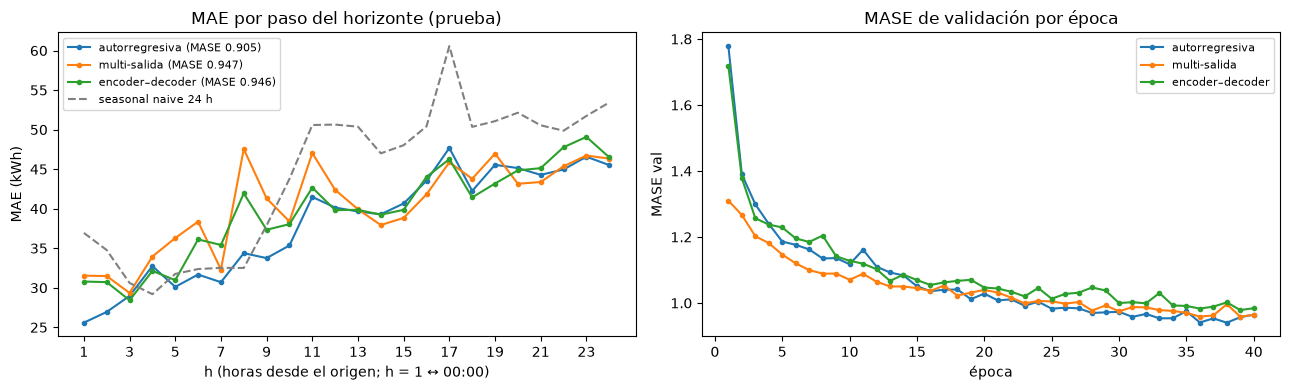

MAE (kWh) en h = 1, 6, 12, 24 y razón h24 / h1:
             1      6     12     24  h24/h1
LSTM-AR  25.59  31.68  40.15  45.52    1.78
LSTM-MO  31.54  38.36  42.38  46.34    1.47
Seq2Seq  30.79  36.12  39.82  46.50    1.51


In [24]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for nom, est in [('LSTM-AR', 'autorregresiva'), ('LSTM-MO', 'multi-salida'), ('Seq2Seq', 'encoder–decoder')]:
    e = error_por_paso(RESULTADOS[nom])
    axs[0].plot(e.index, e.values, marker='o', ms=3, label=f'{est} (MASE {METRICAS[nom]["MASE"]:.3f})')
    hh = HISTORIALES[nom]
    axs[1].plot(hh['epoca'], hh['MASE_val'], marker='o', ms=3, label=est)
e = error_por_paso(RESULTADOS['SeasonalNaive24'])
axs[0].plot(e.index, e.values, ls='--', color='gray', label='seasonal naive 24 h')
axs[0].set(title='MAE por paso del horizonte (prueba)', xlabel='h (horas desde el origen; h = 1 ↔ 00:00)',
           ylabel='MAE (kWh)', xticks=range(1, 25, 2)); axs[0].legend(fontsize=8)
axs[1].set(title='MASE de validación por época', xlabel='época', ylabel='MASE val'); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(REPORTS, 'estrategias_multipaso.png'), dpi=130); plt.show()

paso = pd.DataFrame({n: error_por_paso(RESULTADOS[n]) for n in ['LSTM-AR', 'LSTM-MO', 'Seq2Seq']})
print('MAE (kWh) en h = 1, 6, 12, 24 y razón h24 / h1:')
print(pd.concat([paso.loc[[1, 6, 12, 24]].T, (paso.loc[24] / paso.loc[1]).rename('h24/h1')], axis=1).round(2))

### 5.5 Curvas de entrenamiento de los modelos propios

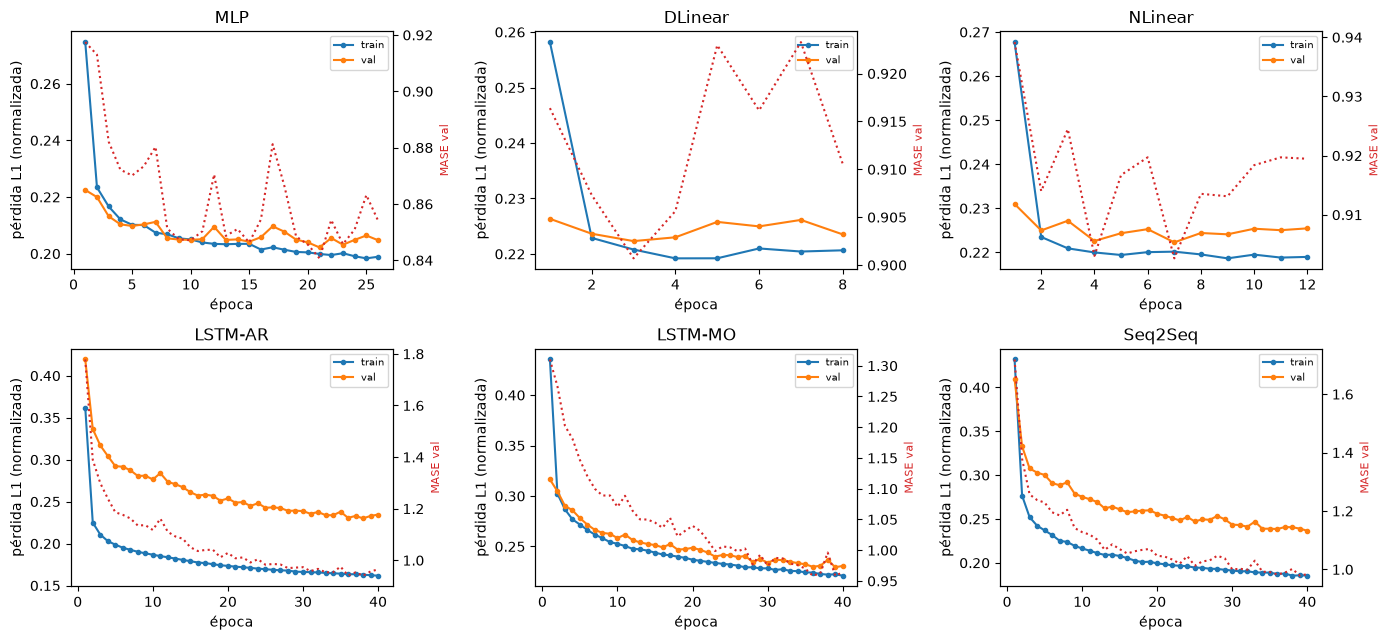

 modelo   L  H meses  norm    lr  batch  params  epocas  mejor_epoca  MAE_val  MASE_val  t_epoca_s  t_total_s  mem_pico_MB
    MLP 168 24  None serie 0.001    512  322328      26           21  32.1800    0.8407     0.6398    17.1466      31.7051
DLinear 168 24  None serie 0.005    512    8112       8            3  34.9228    0.9007     0.5803     4.8228      22.6763
NLinear 168 24  None serie 0.005    512    4056      12            7  34.9128    0.9026     0.5657     6.9882      19.8477
LSTM-AR 168 24  None serie 0.001    512   52545      40           38  35.9412    0.9403     4.0471   171.4794     583.0332
LSTM-MO 168 24  None serie 0.001    512   58648      40           39  36.9787    0.9586     3.9902   164.3967     559.3628
Seq2Seq 168 24  None serie 0.001    512  105025      40           40  37.7852    0.9841     7.9094   325.9755     560.8965


In [25]:
propios = ['MLP', 'DLinear', 'NLinear', 'LSTM-AR', 'LSTM-MO', 'Seq2Seq']
fig, axs = plt.subplots(2, 3, figsize=(14, 6.5), sharex=False)
for ax, nom in zip(axs.ravel(), propios):
    hh = HISTORIALES[nom]
    ax.plot(hh['epoca'], hh['loss_train'], marker='o', ms=3, label='train')
    ax.plot(hh['epoca'], hh['loss_val'], marker='o', ms=3, label='val')
    ax2 = ax.twinx(); ax2.plot(hh['epoca'], hh['MASE_val'], color='C3', ls=':', label='MASE val')
    ax2.set_ylabel('MASE val', color='C3', fontsize=8)
    ax.set(title=nom, xlabel='época', ylabel='pérdida L1 (normalizada)'); ax.legend(fontsize=7, loc='upper right')
plt.tight_layout(); plt.savefig(os.path.join(REPORTS, 'curvas_perdida_propios.png'), dpi=130); plt.show()

tabla_iter = pd.DataFrame(ITERACIONES)
tabla_iter.to_csv(os.path.join(REPORTS, 'tabla_iteraciones.csv'), index=False)
print(tabla_iter[['modelo', 'L', 'H', 'meses', 'norm', 'lr', 'batch', 'params', 'epocas', 'mejor_epoca',
                  'MAE_val', 'MASE_val', 't_epoca_s', 't_total_s', 'mem_pico_MB']].round(4).to_string(index=False))

### Resultados parciales (baselines + modelos propios)

`tabla_comparativa()` arma la tabla de la sección 6 con todo lo que esté en `METRICAS`/`INFO` (ordenada por MASE) y
`guardar_pronosticos()` escribe el archivo de pronósticos de prueba `unique_id, ds, modelo, y_hat` (+ P10/P50/P90
cuando existan). Ambas se vuelven a llamar al final, cuando estén todos los modelos.

In [26]:
def tabla_comparativa():
    filas = []
    for nom, m in METRICAS.items():
        filas.append({'modelo': nom, **INFO[nom], **m})
    tab = pd.DataFrame(filas).sort_values('MASE').reset_index(drop=True)
    cols = ['modelo', 'familia', 'L', 'estrategia', 'covariables', 'params', 'params_entrenables',
            't_entrenamiento_s', 't_inferencia_s', 'hardware', 'MAE', 'RMSE', 'WAPE', 'MAPE', 'MASE', 'MASE_navidad']
    cols += [c for c in ('MASE_H168', 'pinball_esc', 'cobertura_80') if c in tab]
    return tab[cols]

def guardar_pronosticos(ruta=os.path.join(REPORTS, 'pronosticos_prueba.parquet')):
    cols = ['unique_id', 'ds', 'modelo', 'y_hat', 'p10', 'p50', 'p90']
    df = pd.concat([r[[c for c in cols if c in r]] for r in RESULTADOS.values()], ignore_index=True)
    df.to_parquet(ruta, index=False)
    print(f'{ruta}: {len(df):,} filas, {df["modelo"].nunique()} modelos')
    return df

tab = tabla_comparativa()
tab.to_csv(os.path.join(REPORTS, 'tabla_comparativa.csv'), index=False)
print(tab.round(4).to_string(index=False))
_ = guardar_pronosticos()

          modelo         familia   L      estrategia  covariables  params  params_entrenables  t_entrenamiento_s  t_inferencia_s                                                              hardware      MAE     RMSE   WAPE   MAPE   MASE  MASE_navidad
             MLP  MLP y lineales 168    multi-salida         True  322328              322328            17.1466          0.0986 i9-13980HX · RTX 4050 Laptop (entrenamiento) · CPU (inferencia final)  33.8712 169.3347 0.0657 0.0879 0.8193        1.3176
         LSTM-AR     Recurrentes 168  autorregresiva         True   52545               52545           171.4794          1.8412 i9-13980HX · RTX 4050 Laptop (entrenamiento) · CPU (inferencia final)  38.2073 192.8451 0.0741 0.0992 0.9046        1.5051
         NLinear  MLP y lineales 168    multi-salida        False    4056                4056             6.9882          0.0100 i9-13980HX · RTX 4050 Laptop (entrenamiento) · CPU (inferencia final)  37.2291 186.4677 0.0722 0.1052 0.9105       

../reports/pronosticos_prueba.parquet: 2,208,000 filas, 10 modelos


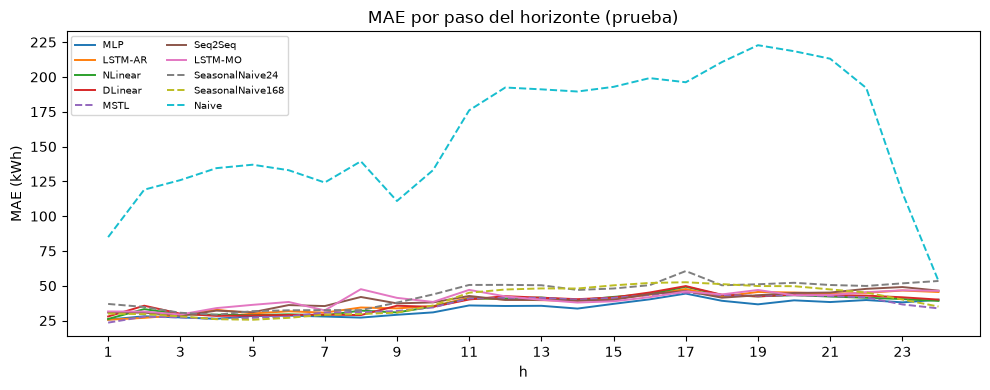

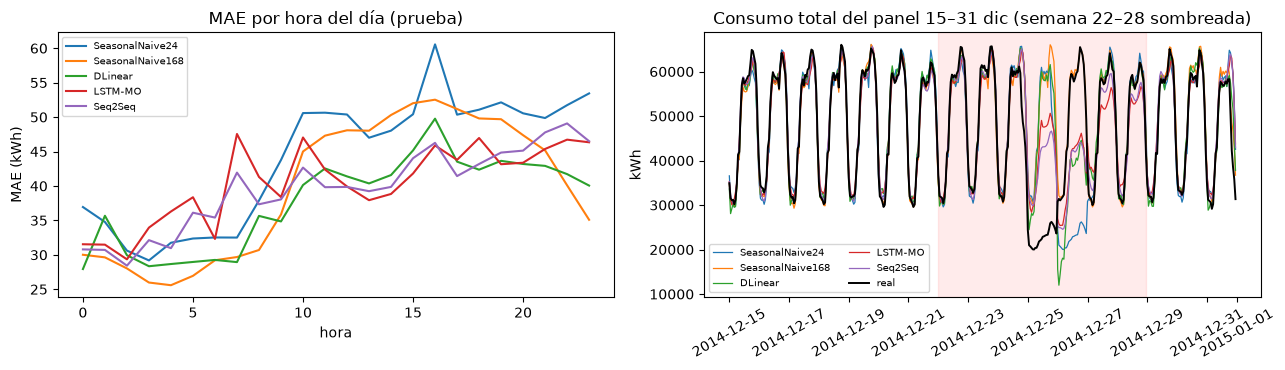

In [27]:
fig, ax = plt.subplots(figsize=(10, 4))
for nom in tab['modelo']:
    e = error_por_paso(RESULTADOS[nom])
    ax.plot(e.index, e.values, lw=1.4, label=nom, ls='--' if INFO[nom]['familia'] == 'Baseline' else '-')
ax.set(title='MAE por paso del horizonte (prueba)', xlabel='h', ylabel='MAE (kWh)', xticks=range(1, 25, 2))
ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.savefig(os.path.join(REPORTS, 'mae_por_paso.png'), dpi=130); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for nom in ['SeasonalNaive24', 'SeasonalNaive168', 'DLinear', 'LSTM-MO', 'Seq2Seq']:
    e = error_por_hora(RESULTADOS[nom]); axs[0].plot(e.index, e.values, label=nom)
    r = RESULTADOS[nom]; d = r[(r['ds'] >= '2014-12-15') & (r['ds'] <= '2015-01-01')]
    axs[1].plot(d.groupby('ds')['y_hat'].sum(), lw=0.9, label=nom)
axs[1].plot(d.groupby('ds')['y'].sum(), color='k', lw=1.4, label='real')
axs[1].axvspan(pd.Timestamp(NAVIDAD[0]), pd.Timestamp(NAVIDAD[1]), color='red', alpha=0.08)
axs[0].set(title='MAE por hora del día (prueba)', xlabel='hora', ylabel='MAE (kWh)'); axs[0].legend(fontsize=7)
axs[1].set(title='Consumo total del panel 15–31 dic (semana 22–28 sombreada)', ylabel='kWh'); axs[1].legend(fontsize=7, ncol=2)
axs[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig(os.path.join(REPORTS, 'error_hora_navidad.png'), dpi=130); plt.show()

**MAPE y clientes de consumo bajo.** Se comparan MAPE y MASE por cliente para el mejor modelo propio:

In [28]:
mejor_propio = min(propios, key=lambda n: METRICAS[n]['MASE'])
r = RESULTADOS[mejor_propio]; pos = r['y'] > 0
mape_cli = ((r['y_hat'] - r['y']).abs()[pos] / r['y'][pos]).groupby(r['unique_id'][pos]).mean()
pc = metricas_por_cliente(r).assign(MAPE=mape_cli).sort_values('MAPE', ascending=False)
print(f'{mejor_propio}: MAPE global {METRICAS[mejor_propio]["MAPE"]:.1%} | mediana por cliente {pc["MAPE"].median():.1%}')
print('clientes con mayor MAPE:'); print(pc.head(5).round(3))
print(f'horas con y < 1 kWh en prueba: {(r["y"] < 1).mean():.2%}')

MLP: MAPE global 8.8% | mediana por cliente 7.3%
clientes con mayor MAPE:
              MAE    RMSE  media_y   MASE   MAPE
unique_id                                       
MT_036      8.693  13.109   38.424  0.664  0.378
MT_130     20.799  36.562   47.125  0.506  0.345
MT_354     19.580  33.391  108.913  1.077  0.234
MT_356      6.855   8.471   35.989  0.370  0.214
MT_162     39.059  59.748  293.695  0.488  0.190
horas con y < 1 kWh en prueba: 0.63%


### 5.6 Árboles: LightGBM global con rezagos (1–24, 168) y calendario

Un solo modelo de *gradient boosting* para los 100 clientes (**global**), entrenado sobre la serie normalizada por
cliente (`Yn`, μ y σ de entrenamiento), así que cada fila es comparable sin importar el tamaño del cliente.

- **Variables:** rezagos `y[t−1], …, y[t−24]` y `y[t−168]` (mismo instante de la semana anterior), más hora, día de la
  semana, mes y feriado como enteros (los árboles cortan por umbrales, así que no necesitan seno/coseno).
- **Estrategia multi-paso: autorregresiva.** El modelo predice una hora; para la hora siguiente el rezago 1 es su
  propia predicción. Al origen (00:00) solo se conocen datos hasta las 23:00 del día anterior, así que en h = 2…24
  los rezagos más cortos ya son predicciones; el rezago 168 siempre es un dato real porque h ≤ 24 < 168.
- **Entrenamiento:** una fila por (cliente, hora) de entrenamiento (~2.2 M filas), pérdida L1 (como los modelos
  propios) y *early stopping* con las filas de validación (jul–sep). Los parámetros reportados son el **número total
  de hojas** de todos los árboles, que es lo que el modelo aprende.

In [29]:
import lightgbm as lgb

LGB_LAGS = list(range(1, 25)) + [168]
MAX_LAG = max(LGB_LAGS)
CAL_INT = np.stack([TIEMPOS.hour.values, TIEMPOS.dayofweek.values, TIEMPOS.month.values,
                    es_feriado.astype(int)], axis=1).astype(np.float32)
LGB_FEATURES = [f'lag_{k}' for k in LGB_LAGS] + ['hour', 'dow', 'month', 'holiday']
LGB_PARAMS = dict(objective='l1', learning_rate=0.05, num_leaves=127, min_data_in_leaf=200,
                  feature_fraction=0.9, bagging_fraction=0.8, bagging_freq=1, verbose=-1, seed=SEED)
VAL_ORIGINS = T_VAL + 24 * np.arange((T_TEST - T_VAL) // 24)


def lgb_matrix(t_start, t_end):
    ts = np.arange(max(t_start, MAX_LAG), t_end)
    lags = np.stack([Yn[:, ts - k] for k in LGB_LAGS], axis=-1)
    cal = np.broadcast_to(CAL_INT[ts], (N, len(ts), CAL_INT.shape[1]))
    X_ = np.concatenate([lags, cal], axis=-1).reshape(-1, len(LGB_FEATURES))
    return X_, Yn[:, ts].reshape(-1)


def train_lightgbm(name, months=None, rounds=3000):
    path = os.path.join(MODELOS, f'{name}.txt')
    t_min = 0 if months is None else idx(TIEMPOS[T_VAL] - pd.DateOffset(months=months))
    if os.path.exists(path) and not RETRAIN:
        booster = lgb.Booster(model_file=path)
        meta = json.load(open(path + '.json'))
        print(f'{name}: modelo cargado de caché ({booster.num_trees()} árboles)')
        return booster, meta
    X_tr, y_tr = lgb_matrix(t_min, T_VAL)
    X_va, y_va = lgb_matrix(T_VAL, T_TEST)
    t = time.perf_counter()
    booster = lgb.train(LGB_PARAMS, lgb.Dataset(X_tr, y_tr, feature_name=LGB_FEATURES, free_raw_data=True),
                        num_boost_round=rounds, valid_sets=[lgb.Dataset(X_va, y_va)],
                        callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(250)])
    meta = dict(t_train_s=time.perf_counter() - t, best_iteration=booster.best_iteration,
                rows=len(y_tr), months=months)
    booster.save_model(path, num_iteration=booster.best_iteration)
    json.dump(meta, open(path + '.json', 'w'))
    print(f'{name}: {meta["best_iteration"]} árboles, {meta["rows"]:,} filas, {meta["t_train_s"]:.1f} s')
    return lgb.Booster(model_file=path), meta


class LightGBMForecaster:
    def __init__(self, nombre, booster, horizon=H):
        self.nombre, self.booster, self.horizon = nombre, booster, horizon

    def predecir(self, hist, t0):
        buf = np.concatenate([(hist[:, t0 - MAX_LAG:t0] - MU) / SD, np.zeros((N, self.horizon))], axis=1)
        for h in range(self.horizon):
            pos = MAX_LAG + h
            lags = np.stack([buf[:, pos - k] for k in LGB_LAGS], axis=1)
            cal = np.broadcast_to(CAL_INT[t0 + h], (N, CAL_INT.shape[1]))
            buf[:, pos] = self.booster.predict(np.concatenate([lags, cal], axis=1))
        return buf[:, MAX_LAG:] * SD + MU


def n_leaves(booster):
    return int(sum(t['num_leaves'] for t in booster.dump_model()['tree_info']))


def val_mase(modelo):
    return _mase(backtest(modelo, origenes=VAL_ORIGINS))


lgb_booster, lgb_meta = train_lightgbm('LightGBM')
lgb_model = LightGBMForecaster('LightGBM', lgb_booster)
registrar(backtest(lgb_model), familia='Árboles', L=MAX_LAG, estrategia='autorregresiva', covariables=True,
          params=n_leaves(lgb_booster), params_entrenables=n_leaves(lgb_booster),
          t_entrenamiento_s=lgb_meta['t_train_s'], hardware=f'{CPU_NAME} · CPU')
imp = pd.Series(lgb_booster.feature_importance('gain'), index=LGB_FEATURES).sort_values(ascending=False)
print('MASE de validación:', round(val_mase(lgb_model), 4))
print('importancia (ganancia, top 8):'); print((imp / imp.sum()).head(8).round(3).to_string())

LightGBM: modelo cargado de caché (2999 árboles)


LightGBM               MAE   34.510  RMSE  168.670  WAPE 0.0670  MAPE 0.090  MASE 0.8542  MASE nav. 1.5048


MASE de validación: 0.8758
importancia (ganancia, top 8):
lag_168    0.573
lag_24     0.144
lag_1      0.139
hour       0.019
lag_23     0.018
lag_2      0.011
lag_20     0.007
lag_22     0.007


El rezago de 168 h concentra más de la mitad de la ganancia, seguido del de 24 h y del de 1 h: el modelo aprende sobre
todo a combinar «el mismo momento de la semana pasada» con «ayer» y «la última hora conocida». Con 3,000 árboles
la pérdida de validación seguía bajando muy despacio (0.1470 → 0.1468 en los últimos 250 árboles), así que el tope
no limita el resultado de forma apreciable.

### 5.7 NeuralForecast: N-HiTS, TCN, PatchTST e iTransformer

Los cuatro se entrenan **una sola vez** con `NeuralForecast.fit` sobre los datos hasta el 2014-09-30, con
`val_size` = jul–sep 2014 para el *early stopping* (es decir, aprenden con datos hasta el 2014-06-30, igual que los
modelos propios). Después, `NFForecaster` los adapta a la interfaz `predecir(hist, t0)`: en cada uno de los 92
orígenes arma un `DataFrame` con la historia hasta las 23:00 del día anterior (y el calendario futuro, que es
conocido) y llama a `nf.predict`. Así **pasan por el mismo `backtest()`** que el resto y el tiempo de inferencia se
mide igual para todos.

| Modelo | Idea | Covariables |
|---|---|---|
| **N-HiTS** | MLP por bloques con *pooling* a varias resoluciones e interpolación jerárquica de la salida | hora, día de la semana y fin de semana |
| **TCN** | convoluciones causales dilatadas (k = 2, d = 1…128 → campo receptivo de 256 h) y un decoder MLP | ver abajo |
| **PatchTST** | Transformer sobre *patches* de 24 h con paso 12 (canal independiente) | no |
| **iTransformer** | Transformer «invertido»: cada **serie** es un token y la atención mezcla clientes | no |

Configuración común: L = 168, H = 24, pérdida MAE, normalización por ventana (`scaler_type='standard'`, el
equivalente de RevIN en Nixtla), lr = 10⁻³, hasta 3,000 pasos con *early stopping* (paciencia de 5 revisiones
cada 100 pasos). Con 6 GB de GPU hay que usar 4 series por lote (`batch_size=4`, 512 ventanas por paso): con 32 series
NeuralForecast arma ~5 GB de ventanas y se queda sin memoria.

**Una trampa de NeuralForecast con las covariables.** Con `scaler_type='standard'`, NeuralForecast normaliza
también las covariables con la media y la desviación **de la ventana de entrada** (más ε = 10⁻⁶). Si una covariable
es constante en las 168 h de la ventana, su desviación es 0: el **mes** dentro de una semana del mismo mes, o el
**feriado** en una semana sin feriados. Cuando el día a pronosticar cambia de mes (o es feriado), su valor futuro
queda dividido entre 10⁻⁶ y la red recibe entradas de ~10⁶. Así se explica lo que observamos:

- **TCN:** la variante con las 8 covariables diverge justo en orígenes de **primer día de mes** (el 1 de agosto en
  validación vale miles de veces el consumo real). Se entrenaron dos variantes y se eligió con el MASE de validación
  la que no usa covariables; solo esa pasa por la prueba.
- **N-HiTS:** con las 8 covariables daba 0.915 en la GPU, pero en la ejecución en CPU el pronóstico del 1 de
  diciembre explotó (−38 millones de kWh): dependía del redondeo. Se reentrenó solo con las covariables que
  **siempre varían dentro de una semana** (hora, día de la semana y fin de semana), lo que elimina el problema.
- **DeepAR** (5.8) usa las 8 covariables y está expuesto al mismo efecto en los cambios de mes y los feriados.

La lección: una normalización por ventana solo es segura para variables que varían dentro de la ventana; el
calendario conocido a futuro hay que pasarlo sin escalar o con codificaciones que no sean constantes en L.

In [30]:
import gc, logging
from neuralforecast import NeuralForecast
from neuralforecast.models import NHITS, TCN, PatchTST, iTransformer, DeepAR
from neuralforecast.losses.pytorch import MAE, DistributionLoss, MQLoss

for _lg in ('pytorch_lightning', 'lightning', 'lightning.pytorch', 'lightning_fabric', 'neuralforecast'):
    logging.getLogger(_lg).setLevel(logging.ERROR)

NF_DF = DF_LARGO.merge(pd.DataFrame(CAL, columns=COLS_CAL).assign(ds=TIEMPOS), on='ds')
NF_DF['unique_id'] = NF_DF['unique_id'].astype(str)
NF_TRAIN = NF_DF[NF_DF['ds'] < TIEMPOS[T_TEST]].reset_index(drop=True)
NF_VAL_SIZE = T_TEST - T_VAL
NF_COMMON = dict(h=H, input_size=168, max_steps=3000, val_check_steps=100, early_stop_patience_steps=5,
                 learning_rate=1e-3, batch_size=4, windows_batch_size=512, scaler_type='standard',
                 random_seed=SEED, enable_progress_bar=False, logger=False, enable_model_summary=False)


def train_nf(name, model, df=NF_TRAIN, val_size=NF_VAL_SIZE):
    path = os.path.join(MODELOS, f'nf_{name}')
    if os.path.exists(os.path.join(path, 'meta.json')) and not RETRAIN:
        nf = NeuralForecast.load(path)
        meta = json.load(open(os.path.join(path, 'meta.json')))
        print(f'{name}: modelo cargado de caché')
        return nf, meta
    gc.collect(); torch.cuda.empty_cache()
    nf = NeuralForecast(models=[model], freq='h')
    if DEVICE.type == 'cuda':
        torch.cuda.reset_peak_memory_stats()
    t = time.perf_counter()
    nf.fit(df=df, val_size=val_size)
    meta = dict(t_train_s=time.perf_counter() - t, params=sum(p.numel() for p in nf.models[0].parameters()),
                params_trainable=sum(p.numel() for p in nf.models[0].parameters() if p.requires_grad),
                mem_peak_MB=_mem_gpu())
    nf.save(path, overwrite=True, save_dataset=False)
    json.dump(meta, open(os.path.join(path, 'meta.json'), 'w'))
    print(f'{name}: {meta["t_train_s"]:.1f} s, {meta["params"]:,} parámetros')
    return nf, meta


class NFForecaster:
    def __init__(self, nombre, nf, col=None, quantile_cols=None, context=336, horizon=H):
        self.nombre, self.nf, self.context, self.horizon = nombre, nf, context, horizon
        self.col, self.quantile_cols = col or nombre, quantile_cols
        self.ids = [str(c) for c in CLIENTES]

    def _frames(self, hist, t0):
        ts = TIEMPOS[t0 - self.context:t0]
        df = pd.DataFrame({'unique_id': np.repeat(self.ids, self.context), 'ds': np.tile(ts, N),
                           'y': hist[:, t0 - self.context:t0].ravel()})
        df = df.join(pd.DataFrame(np.tile(CAL[t0 - self.context:t0], (N, 1)), columns=COLS_CAL))
        tf = TIEMPOS[t0:t0 + self.horizon]
        futr = pd.DataFrame({'unique_id': np.repeat(self.ids, self.horizon), 'ds': np.tile(tf, N)})
        futr = futr.join(pd.DataFrame(np.tile(CAL[t0:t0 + self.horizon], (N, 1)), columns=COLS_CAL))
        return df, futr

    def predecir(self, hist, t0):
        df, futr = self._frames(hist, t0)
        fc = self.nf.predict(df=df, futr_df=futr)
        fc = fc.reset_index() if 'unique_id' not in fc.columns else fc
        fc['unique_id'] = pd.Categorical(fc['unique_id'], categories=self.ids)
        fc = fc.sort_values(['unique_id', 'ds'])
        yhat = fc[self.col].to_numpy().reshape(N, self.horizon)
        if self.quantile_cols:
            q = np.stack([fc[c].to_numpy().reshape(N, self.horizon) for c in self.quantile_cols], axis=-1)
            return yhat, q
        return yhat


def run_nf(name, model, familia, estrategia, covariables, **kw):
    nf, meta = train_nf(name, model)
    res = backtest(NFForecaster(name, nf, **kw))
    registrar(res, familia=familia, L=NF_COMMON['input_size'], estrategia=estrategia, covariables=covariables,
              params=meta['params'], params_entrenables=meta['params_trainable'],
              t_entrenamiento_s=meta['t_train_s'], hardware=HARDWARE)
    return nf, meta, res

In [31]:
TCN_ARGS = dict(kernel_size=2, dilations=[1, 2, 4, 8, 16, 32, 64, 128], loss=MAE())
tcn_candidates = {}
for name, exog in [('TCN', COLS_CAL), ('TCN-noexog', None)]:
    nf_, meta_ = train_nf(name, TCN(**NF_COMMON, futr_exog_list=exog, **TCN_ARGS))
    r = backtest(NFForecaster(name, nf_, col='TCN'), origenes=VAL_ORIGINS)
    worst = (r['y_hat'] - r['y']).abs().groupby(r['origen']).mean().sort_values().tail(1)
    tcn_candidates[name] = dict(nf=nf_, meta=meta_, exog=exog is not None, MASE_val=_mase(r))
    print(f'{name:<11} MASE val {_mase(r):8.4f} | peor origen de validación: {worst.index[0]} (MAE {worst.iat[0]:,.0f} kWh)')
tcn_best = min(tcn_candidates, key=lambda k: tcn_candidates[k]['MASE_val'])
print('elegido con validación:', tcn_best)
tcn = tcn_candidates[tcn_best]
registrar(backtest(NFForecaster('TCN', tcn['nf'], col='TCN')), familia='Residuales y convolucionales', L=168,
          estrategia='multi-salida', covariables=tcn['exog'], params=tcn['meta']['params'],
          params_entrenables=tcn['meta']['params_trainable'], t_entrenamiento_s=tcn['meta']['t_train_s'],
          hardware=HARDWARE)

NF_SAFE_EXOG = ['hora_sin', 'hora_cos', 'dow_sin', 'dow_cos', 'finde']
nhits_nf, nhits_meta = train_nf('NHITS-cal5', NHITS(**NF_COMMON, futr_exog_list=NF_SAFE_EXOG, loss=MAE()))
registrar(backtest(NFForecaster('NHITS', nhits_nf)), familia='Residuales y convolucionales', L=168,
          estrategia='multi-salida', covariables=True, params=nhits_meta['params'],
          params_entrenables=nhits_meta['params_trainable'], t_entrenamiento_s=nhits_meta['t_train_s'],
          hardware=HARDWARE)
patchtst, patchtst_meta, _ = run_nf('PatchTST', PatchTST(**NF_COMMON, patch_len=24, stride=12, loss=MAE()),
                                    'Atención', 'multi-salida', False)
itrans, itrans_meta, _ = run_nf('iTransformer', iTransformer(**dict(NF_COMMON, batch_size=32), n_series=N,
                                                             hidden_size=128, n_heads=8, loss=MAE()),
                                'Atención', 'multi-salida', False)

TCN: modelo cargado de caché


TCN         MASE val  54.4281 | peor origen de validación: 2014-06-30 23:00:00 (MAE 148,707 kWh)
TCN-noexog: modelo cargado de caché


TCN-noexog  MASE val   0.8227 | peor origen de validación: 2014-08-31 23:00:00 (MAE 43 kWh)
elegido con validación: TCN-noexog


TCN                    MAE   33.868  RMSE  190.112  WAPE 0.0657  MAPE 0.088  MASE 0.8082  MASE nav. 1.5435
NHITS-cal5: modelo cargado de caché


NHITS                  MAE   33.916  RMSE  207.157  WAPE 0.0658  MAPE 0.085  MASE 0.8064  MASE nav. 1.6471
PatchTST: modelo cargado de caché


PatchTST               MAE   37.207  RMSE  182.749  WAPE 0.0722  MAPE 0.102  MASE 0.8945  MASE nav. 1.6747
iTransformer: modelo cargado de caché


iTransformer           MAE   31.347  RMSE  162.684  WAPE 0.0608  MAPE 0.079  MASE 0.7519  MASE nav. 1.2524


**Lectura.** iTransformer es el mejor modelo hasta aquí (MASE 0.752) y también el mejor en la semana de Navidad
(1.252). Es el único que **mezcla clientes**: la atención se calcula entre series, así que el pronóstico de un
cliente usa lo que están haciendo los demás ese mismo día. Eso ayuda justo cuando todo el panel cambia de régimen a la
vez (feriados, fines de semana largos). N-HiTS con covariables seguras (0.806) y el TCN sin covariables (0.808) superan al
MLP, mientras que PatchTST (0.895), que trata cada serie por separado y sin calendario, queda cerca de
DLinear/NLinear.

### 5.8 Probabilístico: DeepAR (pinball loss y cobertura P10–P90)

DeepAR (NeuralForecast) es una LSTM autorregresiva que, en lugar de un valor, predice los parámetros de una
distribución **t de Student** para cada hora; al pronosticar muestrea 100 trayectorias y de ellas salen la mediana
(P50, que se usa como pronóstico puntual porque minimiza el MAE) y el intervalo del 80 % (P10–P90). Se entrena con la
verosimilitud de la t de Student; para el *early stopping* se usa la pérdida de cuantiles (`MQLoss`) en validación.
Recibe el calendario como covariable futura. Hay que limitar la inferencia a lotes de 64 ventanas: con todas a la vez
(100 trayectorias × 2,208 ventanas de validación) no cabe en los 6 GB de la GPU.

Métricas probabilísticas (sección 4): **pinball** promedio en P10/P50/P90, dividido por la escala MASE de cada
cliente (así es comparable entre clientes) y **cobertura** = fracción de horas reales dentro de [P10, P90]
(ideal: 80 %).

In [32]:
DEEPAR_Q = ['DeepAR-lo-80', 'DeepAR-median', 'DeepAR-hi-80']
deepar, deepar_meta = train_nf('DeepAR', DeepAR(**dict(NF_COMMON, learning_rate=5e-4), lstm_n_layers=2, lstm_hidden_size=128,
                                                futr_exog_list=COLS_CAL, trajectory_samples=100,
                                                inference_windows_batch_size=64, valid_batch_size=4,
                                                loss=DistributionLoss('StudentT', level=[80]),
                                                valid_loss=MQLoss(level=[80])))
deepar_model = NFForecaster('DeepAR', deepar, col='DeepAR-median', quantile_cols=DEEPAR_Q)
registrar(backtest(deepar_model), familia='Probabilísticos', L=NF_COMMON['input_size'], estrategia='autorregresiva',
          covariables=True, params=deepar_meta['params'], params_entrenables=deepar_meta['params_trainable'],
          t_entrenamiento_s=deepar_meta['t_train_s'], hardware=HARDWARE)

DeepAR: modelo cargado de caché


DeepAR                 MAE   49.978  RMSE  218.233  WAPE 0.0970  MAPE 0.139  MASE 1.2192  MASE nav. 1.8150


### 5.9 Fundacional: Chronos-Bolt zero-shot

`amazon/chronos-bolt-small` (48 M de parámetros) se usa **sin entrenar ni ajustar nada**: en cada origen recibe las
últimas 2,048 horas de consumo crudo de cada cliente (≈ 12 semanas; el modelo se normaliza solo) y devuelve
directamente P10, P50 y P90 para las 24 horas siguientes con `predict_quantiles`. El pronóstico puntual es la mediana.
Para Chronos solo se mide el tiempo de inferencia. (Si `data/chronos-bolt-small` no existe, se descarga de Hugging
Face.)

In [33]:
from chronos import BaseChronosPipeline

CHRONOS_ID = 'amazon/chronos-bolt-small'
CHRONOS_LOCAL = os.path.join(DATA, 'chronos-bolt-small')
CHRONOS_CONTEXT = 2048
chronos_pipe = BaseChronosPipeline.from_pretrained(CHRONOS_LOCAL if os.path.exists(CHRONOS_LOCAL) else CHRONOS_ID,
                                                   device_map=DEVICE.type, torch_dtype=torch.float32)
chronos_params = sum(p.numel() for p in chronos_pipe.model.parameters())


class ChronosForecaster:
    def __init__(self, nombre, pipe, horizon=H, context=CHRONOS_CONTEXT):
        self.nombre, self.pipe, self.horizon, self.context = nombre, pipe, horizon, context

    @torch.no_grad()
    def predecir(self, hist, t0):
        ctx = torch.as_tensor(hist[:, max(0, t0 - self.context):t0], dtype=torch.float32)
        q, _ = self.pipe.predict_quantiles(ctx, prediction_length=self.horizon, quantile_levels=[0.1, 0.5, 0.9])
        q = q.float().cpu().numpy()
        return q[..., 1], q


chronos_model = ChronosForecaster('Chronos-Bolt', chronos_pipe)
registrar(backtest(chronos_model), familia='Fundacional', L=CHRONOS_CONTEXT, estrategia='multi-salida (cuantiles)',
          covariables=False, params=chronos_params, params_entrenables=0, t_entrenamiento_s=0.0, hardware=HARDWARE)
print(f'parámetros: {chronos_params:,} (ninguno se entrena) | inferencia 92 orígenes: '
      f'{INFO["Chronos-Bolt"]["t_inferencia_s"]:.1f} s | MASE de validación: {val_mase(chronos_model):.4f}')

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

Chronos-Bolt           MAE   31.702  RMSE  199.863  WAPE 0.0615  MAPE 0.081  MASE 0.7698  MASE nav. 1.4426


parámetros: 47,718,016 (ninguno se entrena) | inferencia 92 orígenes: 321.1 s | MASE de validación: 0.7793


                MASE  pinball_esc  cobertura_80
DeepAR        1.2192       0.4166        0.6086
Chronos-Bolt  0.7698       0.2573        0.7999


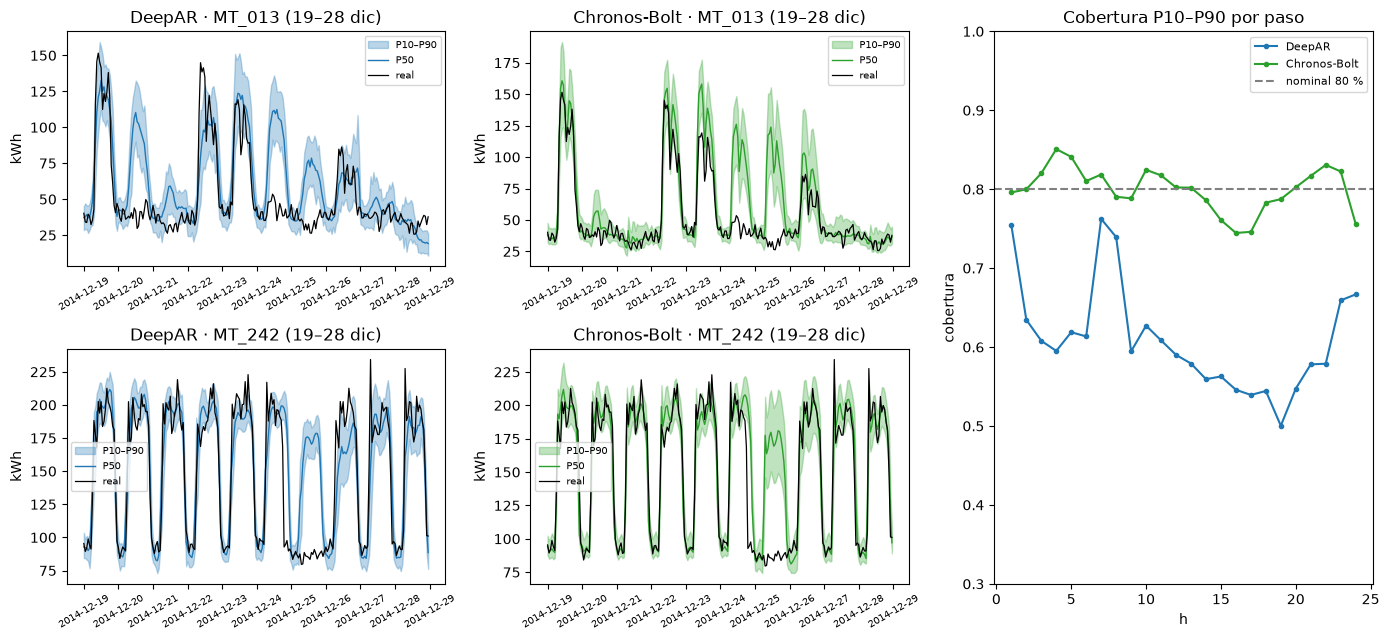

In [34]:
prob = pd.DataFrame({m: {k: METRICAS[m][k] for k in ('MASE', 'pinball_esc', 'cobertura_80')} for m in ('DeepAR', 'Chronos-Bolt')}).T
print(prob.round(4).to_string())
cov_h = pd.DataFrame({m: RESULTADOS[m].assign(ok=lambda d: (d['y'] >= d['p10']) & (d['y'] <= d['p90'])).groupby('h')['ok'].mean()
                      for m in ('DeepAR', 'Chronos-Bolt')})

fig = plt.figure(figsize=(14, 6.5))
gs = fig.add_gridspec(2, 3)
for j, (cli, m) in enumerate([(c, m) for c in (CLIENTES[0], CLIENTES[57]) for m in ('DeepAR', 'Chronos-Bolt')]):
    ax = fig.add_subplot(gs[j // 2, j % 2])
    r = RESULTADOS[m]; d = r[(r['unique_id'] == cli) & (r['ds'] >= '2014-12-19') & (r['ds'] < '2014-12-29')]
    ax.fill_between(d['ds'], d['p10'], d['p90'], alpha=0.3, color='C0' if m == 'DeepAR' else 'C2', label='P10–P90')
    ax.plot(d['ds'], d['p50'], lw=1, color='C0' if m == 'DeepAR' else 'C2', label='P50')
    ax.plot(d['ds'], d['y'], color='k', lw=0.9, label='real')
    ax.set(title=f'{m} · {cli} (19–28 dic)', ylabel='kWh'); ax.tick_params(axis='x', rotation=30, labelsize=7)
    ax.legend(fontsize=7)
ax = fig.add_subplot(gs[:, 2])
for m, c in (('DeepAR', 'C0'), ('Chronos-Bolt', 'C2')):
    ax.plot(cov_h.index, cov_h[m], marker='o', ms=3, color=c, label=m)
ax.axhline(0.8, color='gray', ls='--', label='nominal 80 %')
ax.set(title='Cobertura P10–P90 por paso', xlabel='h', ylabel='cobertura', ylim=(0.3, 1)); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(REPORTS, 'probabilisticos.png'), dpi=130); plt.show()

**Lectura.** Chronos-Bolt, sin ver un solo dato de entrenamiento de este panel, queda **segundo en MASE (0.770)** y
está **bien calibrado**: su intervalo P10–P90 contiene el 80.0 % de las horas reales (el nominal) y su pinball es
0.257. DeepAR queda peor que el seasonal naive (MASE 1.219) y sus intervalos son **demasiado estrechos**: cubren solo
el 61 % y la cobertura cae con el paso del horizonte, porque al muestrear trayectorias autorregresivas la incertidumbre
real crece más rápido que la que el modelo cree tener. En la gráfica se ve el tipo de error: DeepAR pronostica un día
laborable el sábado 20 y el 25 de diciembre para MT_013, mientras que Chronos **abre el intervalo** el 25 (no sabe
si será feriado) y lo cierra el resto de los días. Un intervalo útil no es el más angosto, sino el que contiene lo
que promete. Parte del problema de DeepAR puede venir de la normalización de covariables descrita en 5.7. Esta configuración de DeepAR tardó 34 min en entrenar, el modelo más caro del laboratorio.

### 5.10 Iteraciones de hiperparámetros

Todas las iteraciones usan **solo validación** (jul–sep 2014): `entrenar` registra la configuración, la pérdida de
entrenamiento y validación por época, MAE y MASE de validación al final de cada época, parámetros, tiempo por época y
total, y memoria pico de GPU. La prueba se usa una sola vez, con la configuración ganadora de cada modelo.

Se itera sobre el **MLP** (el mejor modelo propio y el más barato, ~15 s por corrida), variando un factor a la vez
respecto a la base (L = 168, 30 meses, normalización por serie, 512 unidades, dropout 0.1, lr = 10⁻³, batch 512):

| Iteración | Qué cambia |
|---|---|
| `MLP-L48`, `MLP-L336` | ventana L = 48 y 336 h |
| `MLP-m3`, `MLP-m12` | solo los últimos 3 o 12 meses de historia antes del 2014-07-01 (la base usa los 30) |
| `MLP-revin` | normalización **por ventana** (RevIN) además de la de serie |
| `MLP-h1024`, `MLP-drop0.3` | capacidad (1,024 unidades) y regularización (dropout 0.3) |
| `MLP-lr3e-4`, `MLP-b128` | learning rate y tamaño de batch |

Además: la **LSTM autorregresiva** con 80 épocas (con 40 terminó todavía mejorando) y, para la gráfica de historia
de la sección 6, DLinear, LSTM-AR, LightGBM y PatchTST con 3 y 12 meses.

In [35]:
build_mlp = lambda c: MLP(c['L'], c['H'], C, oculto=c.get('oculto', 512), dropout=c.get('dropout', 0.1))
build_dlinear = lambda c: DLinear(c['L'], c['H'])
build_lstm_ar = lambda c: LSTMAutorregresiva(C, c['oculto'], c['capas'], c['dropout'])

MLP_CONFIGS = {
    'MLP': {},
    'MLP-L48': dict(L=48), 'MLP-L336': dict(L=336),
    'MLP-m3': dict(meses=3), 'MLP-m12': dict(meses=12),
    'MLP-revin': dict(norm='ventana'),
    'MLP-h1024': dict(oculto=1024), 'MLP-drop0.3': dict(dropout=0.3),
    'MLP-lr3e-4': dict(lr=3e-4), 'MLP-b128': dict(batch=128),
}
for name, changes in MLP_CONFIGS.items():
    if name != 'MLP':
        entrenar(name, build_mlp, **changes)
entrenar('LSTM-AR-e80', build_lstm_ar, epocas=80, paciencia=8, **arq)
for m in (3, 12):
    entrenar(f'DLinear-m{m}', build_dlinear, meses=m, lr=5e-3)
    entrenar(f'LSTM-AR-m{m}', build_lstm_ar, meses=m, **arq)

MLP-L48: pesos cargados de caché (31 épocas, MASE val 0.9166)
MLP-L336: pesos cargados de caché (14 épocas, MASE val 0.8349)
MLP-m3: pesos cargados de caché (6 épocas, MASE val 1.0365)
MLP-m12: pesos cargados de caché (18 épocas, MASE val 0.8418)
MLP-revin: pesos cargados de caché (25 épocas, MASE val 0.8258)
MLP-h1024: pesos cargados de caché (30 épocas, MASE val 0.8264)
MLP-drop0.3: pesos cargados de caché (19 épocas, MASE val 0.8606)
MLP-lr3e-4: pesos cargados de caché (33 épocas, MASE val 0.8229)
MLP-b128: pesos cargados de caché (25 épocas, MASE val 0.8527)
LSTM-AR-e80: pesos cargados de caché (80 épocas, MASE val 0.9028)
DLinear-m3: pesos cargados de caché (17 épocas, MASE val 0.9071)
LSTM-AR-m3: pesos cargados de caché (15 épocas, MASE val 1.3154)
DLinear-m12: pesos cargados de caché (7 épocas, MASE val 0.9089)
LSTM-AR-m12: pesos cargados de caché (40 épocas, MASE val 0.9364)


     modelo   L  H  meses    norm  oculto  dropout     lr  batch  params  epocas  mejor_epoca  MAE_val  MASE_val  t_epoca_s  t_total_s  mem_pico_MB
 MLP-lr3e-4 168 24     30   serie   512.0      0.1 0.0003    512  322328      33           28  31.1740    0.8229     0.8777    29.8268      31.3101
  MLP-revin 168 24     30 ventana   512.0      0.1 0.0010    512  322330      25           20  31.2605    0.8258     0.9961    25.5397      43.1421
  MLP-h1024 168 24     30   serie  1024.0      0.1 0.0010    512  906776      30           25  31.5411    0.8264     0.9404    29.1439      48.8701
   MLP-L336 336 24     30   serie   512.0      0.1 0.0010    512  408344      14            9  31.6826    0.8349     1.0726    15.5925      46.8843
        MLP 168 24     30   serie   512.0      0.1 0.0010    512  322328      26           21  32.1800    0.8407     0.6398    17.1466      31.7051
    MLP-m12 168 24     12   serie   512.0      0.1 0.0010    512  322328      18           13  31.9732    0.8418

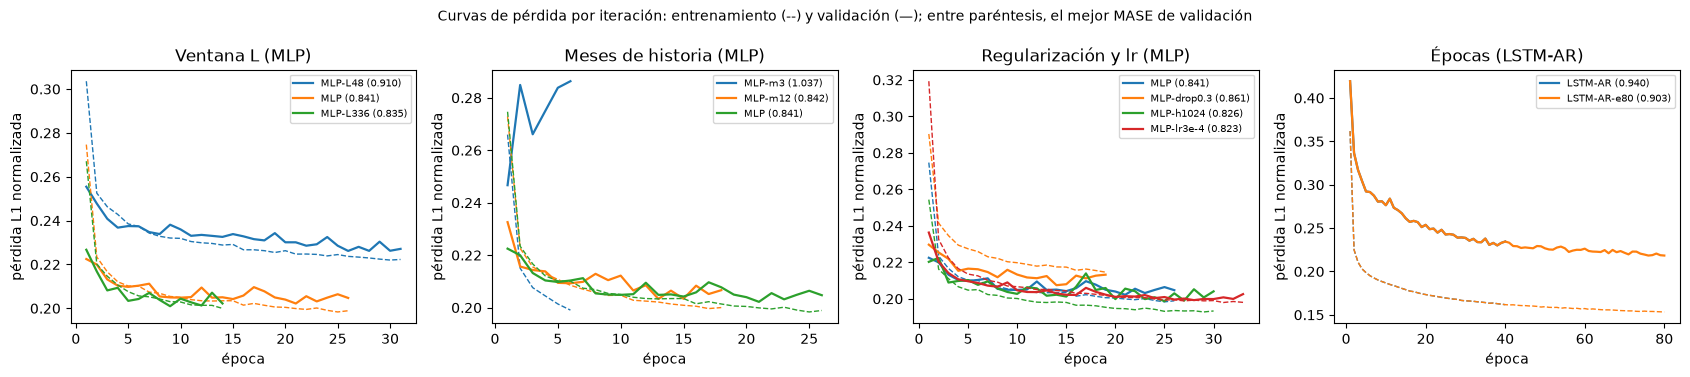

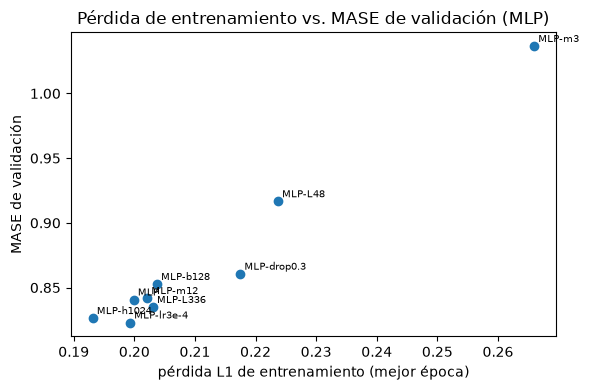

correlación de Spearman entre pérdida de entrenamiento y MASE de validación: 0.93


In [36]:
def iteration_table(prefixes=('MLP', 'DLinear', 'NLinear', 'LSTM', 'Seq2Seq')):
    tab = pd.DataFrame([r for r in ITERACIONES if 'series' not in r and 't_val' not in r and r['seed'] == SEED])
    tab = tab[tab['modelo'].str.startswith(prefixes)].copy()
    tab['meses'] = tab['meses'].fillna(30).astype(int)
    for k, v in dict(oculto=512, dropout=0.1).items():
        tab.loc[tab['modelo'].str.startswith('MLP'), k] = tab.loc[tab['modelo'].str.startswith('MLP'), k].fillna(v)
    return tab


tabla_iter = iteration_table()
tabla_iter.to_csv(os.path.join(REPORTS, 'tabla_iteraciones.csv'), index=False)
print(tabla_iter[['modelo', 'L', 'H', 'meses', 'norm', 'oculto', 'dropout', 'lr', 'batch', 'params', 'epocas',
                  'mejor_epoca', 'MAE_val', 'MASE_val', 't_epoca_s', 't_total_s', 'mem_pico_MB']]
      .sort_values('MASE_val').round(4).to_string(index=False))

fig, axs = plt.subplots(1, 4, figsize=(17, 3.8))
groups = [('Ventana L (MLP)', ['MLP-L48', 'MLP', 'MLP-L336']),
          ('Meses de historia (MLP)', ['MLP-m3', 'MLP-m12', 'MLP']),
          ('Regularización y lr (MLP)', ['MLP', 'MLP-drop0.3', 'MLP-h1024', 'MLP-lr3e-4']),
          ('Épocas (LSTM-AR)', ['LSTM-AR', 'LSTM-AR-e80'])]
for ax, (title, names) in zip(axs, groups):
    for j, nom in enumerate(names):
        hh = HISTORIALES[nom]
        ax.plot(hh['epoca'], hh['loss_train'], ls='--', color=f'C{j}', lw=1)
        ax.plot(hh['epoca'], hh['loss_val'], color=f'C{j}', lw=1.6, label=f'{nom} ({hh["MASE_val"].min():.3f})')
    ax.set(title=title, xlabel='época', ylabel='pérdida L1 normalizada'); ax.legend(fontsize=7)
fig.suptitle('Curvas de pérdida por iteración: entrenamiento (--) y validación (—); entre paréntesis, el mejor MASE de validación',
             fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(REPORTS, 'curvas_iteraciones.png'), dpi=130); plt.show()

mlp_rows = tabla_iter[tabla_iter['modelo'].str.startswith('MLP') & (tabla_iter['norm'] == 'serie')]
final_train = {n: HISTORIALES[n].set_index('epoca').loc[int(r), 'loss_train']
               for n, r in zip(mlp_rows['modelo'], mlp_rows['mejor_epoca'])}
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(list(final_train.values()), mlp_rows['MASE_val'])
for n, x, yv in zip(mlp_rows['modelo'], final_train.values(), mlp_rows['MASE_val']):
    ax.annotate(n, (x, yv), fontsize=7, xytext=(3, 3), textcoords='offset points')
ax.set(title='Pérdida de entrenamiento vs. MASE de validación (MLP)', xlabel='pérdida L1 de entrenamiento (mejor época)',
       ylabel='MASE de validación')
plt.tight_layout(); plt.savefig(os.path.join(REPORTS, 'train_vs_val.png'), dpi=130); plt.show()
rho = pd.Series(final_train).corr(mlp_rows.set_index('modelo')['MASE_val'], method='spearman')
print(f'correlación de Spearman entre pérdida de entrenamiento y MASE de validación: {rho:.2f}')

**Lectura de las iteraciones (solo validación).**

- **Ventana L.** 48 h es claramente peor (0.917): el modelo no ve el mismo día de la semana anterior. 336 h mejora
  un poco a 168 (0.835 vs. 0.841) a cambio de 27 % más parámetros: lo esencial es cubrir al menos una semana.
- **Historia.** Con 3 meses el MLP sobreajusta desde la primera época (la pérdida de entrenamiento baja mientras la
  de validación sube) y queda peor que el seasonal naive; 12 meses ya bastan para igualar a los 30 (0.842 vs. 0.841).
- **Normalización.** RevIN (por ventana) mejora a la base (0.826 vs. 0.841): la red ya no tiene que extrapolar
  cambios de nivel de los clientes entre 2012 y 2014.
- **Capacidad, regularización y optimización.** Bajar el lr a 3·10⁻⁴ es lo que más ayuda (0.823); duplicar la
  capa oculta, casi igual (0.826) con 2.8× parámetros; dropout 0.3 y batch 128 empeoran.
- **LSTM-AR con 80 épocas** baja de 0.940 a 0.903: con 40 épocas estaba subentrenada, como sugerían sus curvas.

**¿Una pérdida de entrenamiento más baja implica siempre un mejor MASE de validación?** No. En el MLP la relación es
fuerte (Spearman 0.93) porque casi todas las iteraciones están lejos del sobreajuste, pero hay contraejemplos: la de
1,024 unidades tiene la menor pérdida de entrenamiento y no es la mejor en validación, y con 3 meses de historia la
pérdida de entrenamiento baja época tras época mientras el MASE de validación empeora. Además, la pérdida solo es
comparable dentro de la misma normalización y el mismo conjunto de entrenamiento (con RevIN o con menos meses cambia
su escala). Por eso la selección se hace con la validación.

**Selección:** `MLP-lr3e-4` como MLP final y `LSTM-AR-e80` como LSTM autorregresiva final; solo ellas se evalúan
en prueba (abajo). En la tabla final reemplazan a sus versiones base.

In [37]:
val_of = lambda n: float(tabla_iter.set_index('modelo').loc[n, 'MASE_val'])
BEST_MLP = min(MLP_CONFIGS, key=val_of)
BEST_LSTM_AR = min(['LSTM-AR', 'LSTM-AR-e80'], key=val_of)
print(f'mejor MLP en validación: {BEST_MLP} ({val_of(BEST_MLP):.4f}) | mejor LSTM-AR: {BEST_LSTM_AR} ({val_of(BEST_LSTM_AR):.4f})')
if BEST_MLP != 'MLP':
    mlp_best, cfg_mlp_best, _ = entrenar_y_evaluar(BEST_MLP, build_mlp, 'MLP y lineales', 'multi-salida', True,
                                                   **MLP_CONFIGS[BEST_MLP])
else:
    mlp_best, cfg_mlp_best = mlp, cfg_mlp
if BEST_LSTM_AR != 'LSTM-AR':
    lstm_ar_best, cfg_ar_best, _ = entrenar_y_evaluar(BEST_LSTM_AR, build_lstm_ar, 'Recurrentes', 'autorregresiva', True,
                                                      epocas=80, paciencia=8, **arq)
else:
    lstm_ar_best, cfg_ar_best = lstm_ar, cfg_ar
SUPERSEDED = {n for n in ('MLP', 'LSTM-AR') if n not in (BEST_MLP, BEST_LSTM_AR)}

mejor MLP en validación: MLP-lr3e-4 (0.8229) | mejor LSTM-AR: LSTM-AR-e80 (0.9028)
MLP-lr3e-4: pesos cargados de caché (33 épocas, MASE val 0.8229)
MLP-lr3e-4             MAE   33.398  RMSE  166.343  WAPE 0.0648  MAPE 0.088  MASE 0.8113  MASE nav. 1.3376
LSTM-AR-e80: pesos cargados de caché (80 épocas, MASE val 0.9028)


LSTM-AR-e80            MAE   35.993  RMSE  177.045  WAPE 0.0698  MAPE 0.091  MASE 0.8619  MASE nav. 1.4094


**Historia de entrenamiento (para la gráfica 3 de la sección 6).** Se reentrenan LightGBM, PatchTST, DLinear, la
LSTM-AR y el MLP con 3, 12 y 30 meses de historia antes del 2014-07-01 y se mide el MASE de **validación**;
seasonal naive y Chronos no dependen de la historia de entrenamiento y quedan como referencias.

In [38]:
class SeasonalNaiveForecaster:
    def __init__(self, nombre='SeasonalNaive24', m=24):
        self.nombre, self.m = nombre, m

    def predecir(self, hist, t0):
        return np.tile(hist[:, t0 - self.m:t0], (1, H // self.m + 1))[:, :H]


HISTORY = {}
for m in (3, 12, None):
    lgb_m = 'LightGBM' if m is None else f'LightGBM-m{m}'
    b, _ = train_lightgbm(lgb_m, months=m)
    pt_name = 'PatchTST' if m is None else f'PatchTST-m{m}'
    pt_df = NF_TRAIN if m is None else NF_TRAIN[NF_TRAIN['ds'] >= TIEMPOS[T_VAL] - pd.DateOffset(months=m)]
    pt_nf, _ = train_nf(pt_name, PatchTST(**NF_COMMON, patch_len=24, stride=12, loss=MAE()), df=pt_df)
    suffix = '' if m is None else f'-m{m}'
    HISTORY[m or 30] = {'LightGBM': val_mase(LightGBMForecaster(lgb_m, b)),
                        'PatchTST': val_mase(NFForecaster(pt_name, pt_nf, col='PatchTST')),
                        'DLinear': val_of(f'DLinear{suffix}'), 'LSTM-AR': val_of(f'LSTM-AR{suffix}'),
                        'MLP': val_of(f'MLP{suffix}')}
HISTORY_REF = {'SeasonalNaive24': val_mase(SeasonalNaiveForecaster()), 'Chronos-Bolt (zero-shot)': val_mase(chronos_model)}
tabla_historia = pd.DataFrame(HISTORY).T.sort_index()
tabla_historia.index.name = 'meses de historia'
print('MASE de validación según los meses de historia de entrenamiento:')
print(tabla_historia.round(4).to_string())
print('referencias (no dependen de la historia):', {k: round(v, 4) for k, v in HISTORY_REF.items()})

LightGBM-m3: modelo cargado de caché (2982 árboles)


PatchTST-m3: modelo cargado de caché


LightGBM-m12: modelo cargado de caché (3000 árboles)
PatchTST-m12: modelo cargado de caché


LightGBM: modelo cargado de caché (2999 árboles)
PatchTST: modelo cargado de caché


MASE de validación según los meses de historia de entrenamiento:
                   LightGBM  PatchTST  DLinear  LSTM-AR     MLP
meses de historia                                              
3                    0.9342    0.9088   0.9071   1.3154  1.0365
12                   0.8842    0.9156   0.9089   0.9364  0.8418
30                   0.8758    0.9135   0.9007   0.9403  0.8407
referencias (no dependen de la historia): {'SeasonalNaive24': 0.9907, 'Chronos-Bolt (zero-shot)': 0.7793}


### 5.11 Modelo local contra global (10 clientes)

El mejor modelo propio (la configuración del MLP elegida en 5.10) se entrena **una vez por cliente** para 10 clientes
elegidos con la semilla fija (`VentanasDataset(..., series=[i])`, mismas épocas máximas, early stopping con la
validación de ese cliente) y se compara con el modelo **global** en esos mismos 10 clientes. Cada modelo local ve
~21,700 ventanas; el global ve las de los 100 clientes (~2.2 M).

In [39]:
LOCAL_IDX = sorted(np.random.default_rng(SEED).choice(N, size=10, replace=False).tolist())
LOCAL_IDS = [CLIENTES[i] for i in LOCAL_IDX]
local_fc = {}
for i in LOCAL_IDX:
    name = f'{BEST_MLP}-local-{CLIENTES[i]}'
    m_i, c_i, _ = entrenar(name, build_mlp, **MLP_CONFIGS[BEST_MLP], series=[i])
    local_fc[i] = PronosticadorTorch(name, m_i, c_i)


class LocalPanelForecaster:
    def __init__(self, nombre, base, local):
        self.nombre, self.base, self.local = nombre, base, local

    def predecir(self, hist, t0):
        out = self.base.predecir(hist, t0)
        for i, fc in self.local.items():
            out[i] = fc.predecir(hist, t0)[i]
        return out


res_local = backtest(LocalPanelForecaster(f'{BEST_MLP}-local', PronosticadorTorch(BEST_MLP, mlp_best, cfg_mlp_best), local_fc))
local_vs_global = pd.DataFrame({
    'consumo medio (kWh/h)': metricas_por_cliente(RESULTADOS[BEST_MLP]).loc[LOCAL_IDS, 'media_y'],
    'MASE global': metricas_por_cliente(RESULTADOS[BEST_MLP]).loc[LOCAL_IDS, 'MASE'],
    'MASE local': metricas_por_cliente(res_local).loc[LOCAL_IDS, 'MASE'],
    'épocas local': [next(r['epocas'] for r in ITERACIONES if r['modelo'] == f'{BEST_MLP}-local-{c}') for c in LOCAL_IDS]})
local_vs_global['mejora del global'] = 1 - local_vs_global['MASE global'] / local_vs_global['MASE local']
local_vs_global = local_vs_global.sort_values('mejora del global', ascending=False)
print(local_vs_global.round(3).to_string())
print(f"\nMASE promedio en los 10 clientes → global {local_vs_global['MASE global'].mean():.4f} | "
      f"local {local_vs_global['MASE local'].mean():.4f} | el global gana en "
      f"{(local_vs_global['MASE global'] < local_vs_global['MASE local']).sum()} de 10")

MLP-lr3e-4-local-MT_046: pesos cargados de caché (20 épocas, MASE val 0.6573)
MLP-lr3e-4-local-MT_050: pesos cargados de caché (25 épocas, MASE val 0.6129)
MLP-lr3e-4-local-MT_083: pesos cargados de caché (40 épocas, MASE val 0.5555)
MLP-lr3e-4-local-MT_174: pesos cargados de caché (8 épocas, MASE val 1.7017)
MLP-lr3e-4-local-MT_247: pesos cargados de caché (25 épocas, MASE val 0.9327)
MLP-lr3e-4-local-MT_268: pesos cargados de caché (19 épocas, MASE val 0.7982)
MLP-lr3e-4-local-MT_279: pesos cargados de caché (34 épocas, MASE val 0.6281)
MLP-lr3e-4-local-MT_319: pesos cargados de caché (30 épocas, MASE val 0.7760)
MLP-lr3e-4-local-MT_357: pesos cargados de caché (26 épocas, MASE val 0.8330)
MLP-lr3e-4-local-MT_360: pesos cargados de caché (32 épocas, MASE val 0.9528)


           consumo medio (kWh/h)  MASE global  MASE local  épocas local  mejora del global
unique_id                                                                                 
MT_174                   152.082        1.065       1.204             8              0.115
MT_247                   416.277        0.622       0.690            25              0.098
MT_268                   209.545        0.839       0.921            19              0.089
MT_319                    90.195        0.888       0.937            30              0.052
MT_360                   502.684        0.793       0.830            32              0.044
MT_357                  1843.176        0.935       0.898            26             -0.042
MT_046                   142.075        0.847       0.806            20             -0.050
MT_279                 11366.141        1.027       0.967            34             -0.062
MT_050                   181.336        0.750       0.684            25             -0.097

**Lectura.** El modelo global gana, pero por poco: MASE promedio de 0.852 frente a 0.861 del local, y es mejor en 5
de los 10 clientes. Los que más se benefician del global son aquellos en los que el modelo local **se detuvo muy
pronto** (MT_174 paró en 8 épocas y mejora 11.5 % con el global): con solo ~21,700 ventanas el MLP de 322 k
parámetros sobreajusta enseguida, y el global le aporta los patrones de hora, día y feriado que aprende de los otros
99 clientes. Los clientes con un perfil propio muy regular (MT_083, MT_050) quedan mejor con su modelo local, que se
especializa en ellos. En costo, el global es un solo entrenamiento de ~30 s; los locales son 10 entrenamientos (100
para todo el panel) y 10 modelos que mantener.

### 5.12 Reentrenamiento mensual y sensibilidad a la semilla

**Reentrenamiento.** El protocolo base entrena una sola vez con datos hasta el 2014-09-30. Aquí se repite la prueba
**reentrenando al inicio de cada mes** con ventana expandible (3 orígenes de entrenamiento: 1-oct, 1-nov y 1-dic).
En cada corte se entrena con todo lo anterior a los 3 últimos meses y esos 3 meses sirven de validación para el
*early stopping*; ese modelo pronostica los días de su mes. La normalización (μ, σ) sigue siendo la de entrenamiento.

- **Mejor modelo de deep learning propio:** el MLP elegido en 5.10.
- **Mejor baseline:** MSTL. Como MSTL ya se reajusta en cada origen en el protocolo base, se comparan tres
  frecuencias: ajustado una sola vez el 1-oct, reajustado al inicio de cada mes y reajustado cada día. Entre ajustes,
  StatsForecast usa `forward` (aplica el modelo ya ajustado a la historia nueva sin reestimarlo).

In [40]:
MONTH_STARTS = [idx('2014-10-01 00:00'), idx('2014-11-01 00:00'), idx('2014-12-01 00:00'), T]
MONTH_NAMES = ['oct', 'nov', 'dic']
month_origins = [ORIGENES[(ORIGENES >= a) & (ORIGENES < b)] for a, b in zip(MONTH_STARTS[:-1], MONTH_STARTS[1:])]


def by_month(res):
    first_hour = res['origen'] + pd.Timedelta(hours=1)
    return {mes: _mase(res[first_hour.dt.month == m]) for mes, m in zip(MONTH_NAMES, (10, 11, 12))}


monthly_parts = []
for k, (t_cut, origs) in enumerate(zip(MONTH_STARTS[:-1], month_origins)):
    if k == 0:
        m_k, c_k = mlp_best, cfg_mlp_best
    else:
        t_val_k = idx(TIEMPOS[t_cut] - pd.DateOffset(months=3))
        m_k, c_k, _ = entrenar(f'{BEST_MLP}-retrain-{TIEMPOS[t_cut]:%Y-%m}', build_mlp, **MLP_CONFIGS[BEST_MLP],
                               t_val=t_val_k, t_test=t_cut)
    monthly_parts.append(backtest(PronosticadorTorch(f'{BEST_MLP} (mensual)', m_k, c_k), origenes=origs))
res_mlp_monthly = pd.concat(monthly_parts, ignore_index=True)

MSTL_VARIANTS = os.path.join(DATA, 'cv_mstl_variantes.parquet')
if os.path.exists(MSTL_VARIANTS) and not RETRAIN:
    cv_mstl_var = pd.read_parquet(MSTL_VARIANTS)
else:
    mk = lambda: StatsForecast(models=[MSTL(season_length=[24, 168], trend_forecaster=AutoETS(model='ZZN'),
                                            alias='MSTL')], freq='h', n_jobs=-1)
    parts = []
    for origs, end in zip(month_origins, MONTH_STARTS[1:]):
        cv = mk().cross_validation(df=DF_LARGO[DF_LARGO['ds'] < TIEMPOS[end - 1] + pd.Timedelta(hours=1)], h=H,
                                   step_size=24, n_windows=len(origs), refit=False, input_size=24 * 7 * 4)
        parts.append(cv.rename(columns={'MSTL': 'MSTL (mensual)'}))
    once = mk().cross_validation(df=DF_LARGO, h=H, step_size=24, n_windows=N_ORIGENES, refit=False,
                                 input_size=24 * 7 * 4).rename(columns={'MSTL': 'MSTL (una vez)'})
    cv_mstl_var = pd.concat(parts, ignore_index=True)[['unique_id', 'ds', 'cutoff', 'MSTL (mensual)']].merge(
        once[['unique_id', 'ds', 'cutoff', 'MSTL (una vez)']], on=['unique_id', 'ds', 'cutoff'])
    cv_mstl_var.to_parquet(MSTL_VARIANTS)

retrain_rows = {
    f'{BEST_MLP}: entrenado una vez': RESULTADOS[BEST_MLP],
    f'{BEST_MLP}: reentrenado cada mes': res_mlp_monthly,
    'MSTL: ajustado una vez (1-oct)': backtest(PronosticosPrecalculados(cv_mstl_var, 'MSTL (una vez)')),
    'MSTL: reajustado cada mes': backtest(PronosticosPrecalculados(cv_mstl_var, 'MSTL (mensual)')),
    'MSTL: reajustado cada día': RESULTADOS['MSTL'],
}
tabla_reentreno = pd.DataFrame({k: {'MASE': _mase(r), 'MAE': (r['y_hat'] - r['y']).abs().mean(), **by_month(r)}
                                for k, r in retrain_rows.items()}).T
print(tabla_reentreno.round(4).to_string())

MLP-lr3e-4-retrain-2014-11: pesos cargados de caché (24 épocas, MASE val 0.7997)
MLP-lr3e-4-retrain-2014-12: pesos cargados de caché (33 épocas, MASE val 0.7591)


                                    MASE      MAE     oct     nov     dic
MLP-lr3e-4: entrenado una vez     0.8113  33.3981  0.7919  0.7067  0.9319
MLP-lr3e-4: reentrenado cada mes  0.8116  33.3983  0.7919  0.7111  0.9284
MSTL: ajustado una vez (1-oct)    0.9391  36.1025  0.8871  0.7818  1.1433
MSTL: reajustado cada mes         0.9385  36.0495  0.8871  0.7823  1.1411
MSTL: reajustado cada día         0.9373  36.0342  0.8867  0.7823  1.1380


**Lectura.** Reentrenar cada mes **casi no cambia el error**: el MLP pasa de 0.8113 a 0.8116 (mejora un poco en
diciembre y empeora un poco en noviembre) y MSTL de 0.9391 (una vez) a 0.9385 (mensual) y 0.9373 (diario). Con 30
meses de historia, un mes más de datos apenas cambia lo que el modelo global aprende, y el patrón de consumo de
oct–dic no tiene un cambio de nivel que obligue a reaprender. En MSTL, además, `forward` vuelve a descomponer la
historia nueva y solo deja fijos los parámetros del ETS de la tendencia, así que ajustar una vez ya se adapta casi
igual que reajustar a diario. Lo que sí cambia por mes es la **dificultad**: noviembre es el mes más fácil y
diciembre el más difícil para todos (feriados del 8, 25 y 26 de diciembre).

In [41]:
SEEDS = [SEED, 7, 2026]
seed_rows = []
for sd in SEEDS:
    name = BEST_MLP if sd == SEED else f'{BEST_MLP}-seed{sd}'
    m_s, c_s, f_s = entrenar(name, build_mlp, **MLP_CONFIGS[BEST_MLP], seed=sd)
    r = RESULTADOS[BEST_MLP] if sd == SEED else backtest(PronosticadorTorch(name, m_s, c_s))
    seed_rows.append(dict(semilla=sd, MASE_val=f_s['MASE_val'], MASE_prueba=_mase(r),
                          MAE_prueba=(r['y_hat'] - r['y']).abs().mean(), epocas=f_s['epocas']))
tabla_semillas = pd.DataFrame(seed_rows).set_index('semilla')
print(tabla_semillas.round(4).to_string())
print(f"\nMASE de prueba: {tabla_semillas['MASE_prueba'].mean():.4f} ± {tabla_semillas['MASE_prueba'].std(ddof=1):.4f} "
      f"(desviación estándar muestral, 3 semillas)")

MLP-lr3e-4: pesos cargados de caché (33 épocas, MASE val 0.8229)
MLP-lr3e-4-seed7: pesos cargados de caché (31 épocas, MASE val 0.8236)
MLP-lr3e-4-seed2026: pesos cargados de caché (20 épocas, MASE val 0.8293)
         MASE_val  MASE_prueba  MAE_prueba  epocas
semilla                                           
42         0.8229       0.8113     33.3981      33
7          0.8236       0.8068     33.4723      31
2026       0.8293       0.8219     33.8108      20

MASE de prueba: 0.8133 ± 0.0077 (desviación estándar muestral, 3 semillas)


**Sensibilidad a la semilla.** Con 3 semillas (42, 7 y 2026) el MLP final da un MASE de prueba de
**0.813 ± 0.008**. La desviación es del mismo orden que varias de las diferencias entre iteraciones de 5.10 (p. ej.
L = 168 contra 336), así que esas diferencias pequeñas **no son concluyentes** con una sola corrida, mientras que
las grandes (MLP frente a las LSTM, ~0.05, o iTransformer frente al MLP, ~0.06) sí están muy por encima del ruido.

## 6. Comparación de resultados

### 6.1 MASE con H = 168

Para los modelos que pueden pronosticar una semana sin reentrenarse (los baselines, LightGBM y las redes
recursivas, que realimentan su predicción; Chronos, que acepta cualquier `prediction_length`) se mide además el MASE
con **H = 168** sobre 13 orígenes semanales dentro de la prueba (el último pronóstico termina el 2014-12-31 a las
23:00). Los modelos multi-salida entrenados para 24 h (MLP, DLinear, NeuralForecast, DeepAR) no aplican.

In [42]:
H_WEEK = 168
ORIG_WEEK = T - H_WEEK * np.arange(13, 0, -1)
assert ORIG_WEEK.min() >= T_TEST and ((ORIG_WEEK - T_TEST) % 24 == 0).all()

CV_WEEK = os.path.join(DATA, 'cv_statsforecast_h168.parquet')
if os.path.exists(CV_WEEK) and not RETRAIN:
    cv_week = pd.read_parquet(CV_WEEK)
else:
    cv_week = StatsForecast(models=[Naive(), SeasonalNaive(24, alias='SeasonalNaive24'),
                                    SeasonalNaive(168, alias='SeasonalNaive168')], freq='h', n_jobs=-1).cross_validation(
        df=DF_LARGO, h=H_WEEK, step_size=H_WEEK, n_windows=len(ORIG_WEEK), refit=False)
    cv_m = StatsForecast(models=[MSTL(season_length=[24, 168], trend_forecaster=AutoETS(model='ZZN'), alias='MSTL')],
                         freq='h', n_jobs=-1).cross_validation(df=DF_LARGO, h=H_WEEK, step_size=H_WEEK,
                                                               n_windows=len(ORIG_WEEK), refit=True, input_size=672)
    cv_week = cv_week.merge(cv_m[['unique_id', 'ds', 'cutoff', 'MSTL']], on=['unique_id', 'ds', 'cutoff'])
    cv_week.to_parquet(CV_WEEK)
assert set(pd.to_datetime(cv_week['cutoff'])) == set(TIEMPOS[ORIG_WEEK - 1])


class TorchForecasterH(PronosticadorTorch):
    def __init__(self, nombre, modelo, cfg, horizon):
        super().__init__(nombre, modelo, cfg)
        self.horizon = horizon

    @torch.no_grad()
    def predecir(self, hist, t0):
        x = (torch.as_tensor(hist[:, t0 - self.L:t0], dtype=torch.float32) - self.mu) / self.sd
        X = torch.cat([x.unsqueeze(-1), torch.as_tensor(CAL[t0 - self.L:t0]).expand(N, -1, -1)], dim=-1).to(DEVICE)
        Xf = torch.as_tensor(CAL[t0:t0 + self.horizon]).expand(N, -1, -1).to(DEVICE)
        return (self.modelo(X, Xf).cpu() * self.sd + self.mu).numpy()


week_models = {
    'LightGBM': LightGBMForecaster('LightGBM', lgb_booster, horizon=H_WEEK),
    'Chronos-Bolt': ChronosForecaster('Chronos-Bolt', chronos_pipe, horizon=H_WEEK),
    BEST_LSTM_AR: TorchForecasterH(BEST_LSTM_AR, lstm_ar_best, cfg_ar_best, H_WEEK),
    'Seq2Seq': TorchForecasterH('Seq2Seq', s2s, cfg_s2s, H_WEEK),
}
for col in ['Naive', 'SeasonalNaive24', 'SeasonalNaive168', 'MSTL']:
    d = cv_week.assign(ae=(cv_week[col] - cv_week['y']).abs())
    METRICAS[col]['MASE_H168'] = float((d.groupby('unique_id')['ae'].mean() / ESCALA).mean())
for nom, fc in week_models.items():
    METRICAS[nom]['MASE_H168'] = _mase(backtest(fc, origenes=ORIG_WEEK, H=H_WEEK))
print('MASE con H = 168 (13 orígenes semanales en prueba):')
print(pd.Series({k: v['MASE_H168'] for k, v in METRICAS.items() if 'MASE_H168' in v}).sort_values().round(4).to_string())

MASE con H = 168 (13 orígenes semanales en prueba):
Chronos-Bolt        0.9300
LightGBM            1.0640
MSTL                1.1133
SeasonalNaive168    1.1151
LSTM-AR-e80         1.1522
SeasonalNaive24     1.1883
Seq2Seq             1.5538
Naive               4.0902


A una semana, **Chronos sigue siendo el mejor** (0.930) y es el único por debajo de 1. LightGBM (1.064) se degrada
menos que las redes recursivas: la LSTM-AR pasa de 0.862 a 1.152 y el seq2seq de 0.946 a 1.553, porque al
realimentar sus propias predicciones durante 168 pasos el error se acumula (están entrenados para 24). Con H = 168 el
seasonal naive de 168 h ya iguala a MSTL: repetir la semana pasada es difícil de superar a ese horizonte.

### 6.2 Tabla comparativa (mejor configuración de cada modelo, ordenada por MASE)

In [43]:
tab = tabla_comparativa()
tab = tab[~tab['modelo'].isin(SUPERSEDED)].reset_index(drop=True)
tab.to_csv(os.path.join(REPORTS, 'tabla_comparativa.csv'), index=False)
FINALES = tab['modelo'].tolist()
show = ['modelo', 'familia', 'L', 'estrategia', 'covariables', 'params', 'params_entrenables', 't_entrenamiento_s',
        't_inferencia_s', 'hardware', 'MAE', 'RMSE', 'WAPE', 'MASE', 'MASE_H168', 'MASE_navidad', 'pinball_esc', 'cobertura_80']
print(tab[show].round(4).to_string(index=False))
pronos = guardar_pronosticos()

          modelo                      familia    L               estrategia  covariables   params  params_entrenables  t_entrenamiento_s  t_inferencia_s                                                              hardware      MAE     RMSE   WAPE   MASE  MASE_H168  MASE_navidad  pinball_esc  cobertura_80
    iTransformer                     Atención  168             multi-salida        False  1211032             1211032           853.9656          1.9752 i9-13980HX · RTX 4050 Laptop (entrenamiento) · CPU (inferencia final)  31.3475 162.6835 0.0608 0.7519        NaN        1.2524          NaN           NaN
    Chronos-Bolt                  Fundacional 2048 multi-salida (cuantiles)        False 47718016                   0             0.0000        321.0855 i9-13980HX · RTX 4050 Laptop (entrenamiento) · CPU (inferencia final)  31.7022 199.8630 0.0615 0.7698     0.9300        1.4426       0.2573        0.7999
           NHITS Residuales y convolucionales  168             multi-salida    

../reports/pronosticos_prueba.parquet: 4,195,200 filas, 19 modelos


La tabla también está en `reports/tabla_comparativa.csv` y los pronósticos de prueba de los 19 modelos evaluados
(incluidas las versiones base del MLP y de la LSTM-AR) en `reports/pronosticos_prueba.parquet`
(`unique_id, ds, modelo, y_hat` y P10/P50/P90 para DeepAR y Chronos). Notas: para LightGBM, los «parámetros» son el
número total de hojas; para Chronos, el tiempo es solo de inferencia y ningún parámetro se entrena; StatsForecast
corre en CPU. El resto se **entrenó** en una RTX 4050 Laptop (6 GB); en esta ejecución final la **inferencia** se hizo en CPU (ver la nota de la sección 0), por eso Chronos tarda 321 s en lugar de los 13 s que tardaba en la GPU.

### 6.3 Gráficas: Pareto, error por paso e historia de entrenamiento

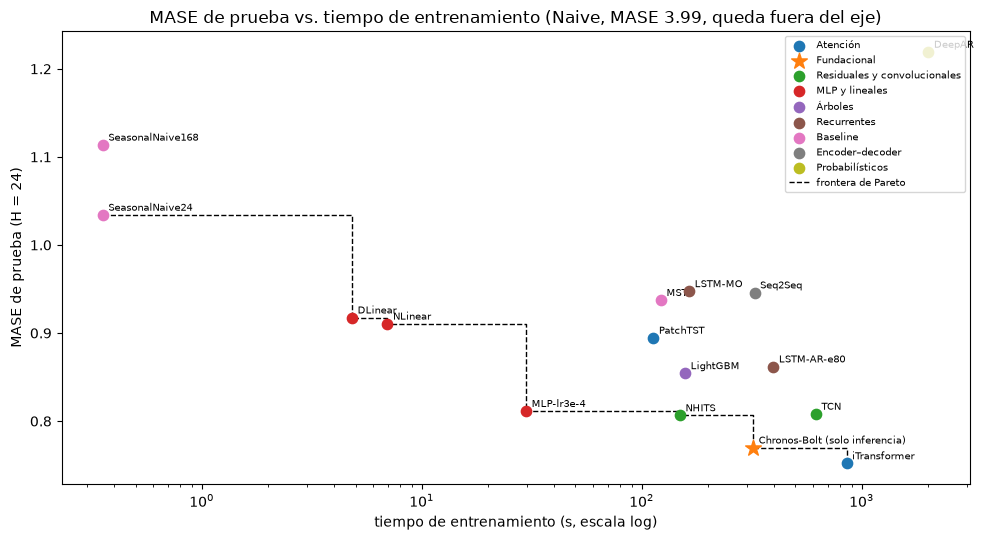

frontera de Pareto: SeasonalNaive24 (1.034) → DLinear (0.917) → NLinear (0.911) → MLP-lr3e-4 (0.811) → NHITS (0.806) → Chronos-Bolt (0.770) → iTransformer (0.752)


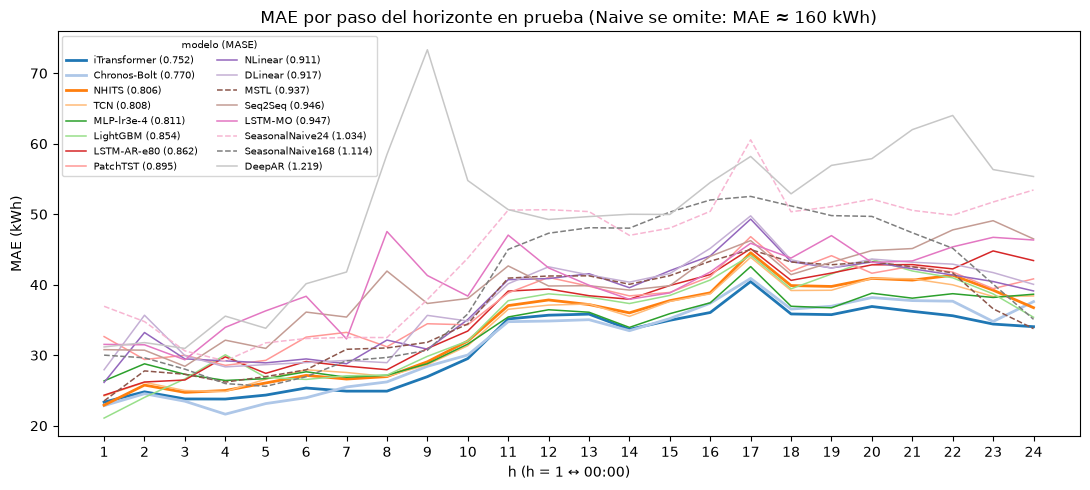

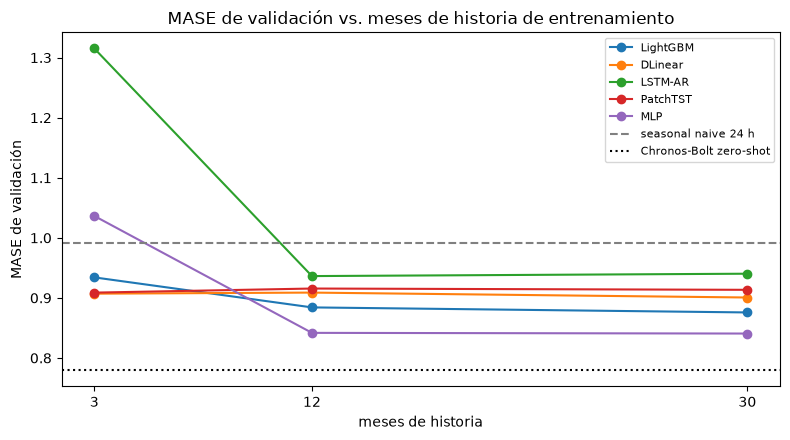

In [44]:
fam_color = {f: f'C{i}' for i, f in enumerate(tab['familia'].unique())}
fig, ax = plt.subplots(figsize=(10, 5.5))
pts = tab[tab['MASE'] < 2].copy()
pts['t_plot'] = np.where(pts['t_entrenamiento_s'] > 0, pts['t_entrenamiento_s'], pts['t_inferencia_s'])
for _, r in pts.iterrows():
    zero = r['t_entrenamiento_s'] == 0
    ax.scatter(r['t_plot'], r['MASE'], color=fam_color[r['familia']], marker='*' if zero else 'o', s=140 if zero else 55,
               label=r['familia'], zorder=3)
    ax.annotate(r['modelo'] + (' (solo inferencia)' if zero else ''), (r['t_plot'], r['MASE']), fontsize=7,
                xytext=(4, 3), textcoords='offset points')
front = pts.sort_values('t_plot')
front = front[front['MASE'] <= front['MASE'].cummin()]
ax.step(front['t_plot'], front['MASE'], where='post', color='k', ls='--', lw=1, label='frontera de Pareto')
h_, l_ = ax.get_legend_handles_labels()
uniq = dict(zip(l_, h_))
ax.legend(uniq.values(), uniq.keys(), fontsize=7, loc='upper right')
ax.set_xscale('log')
ax.set(title='MASE de prueba vs. tiempo de entrenamiento (Naive, MASE 3.99, queda fuera del eje)',
       xlabel='tiempo de entrenamiento (s, escala log)', ylabel='MASE de prueba (H = 24)')
plt.tight_layout(); plt.savefig(os.path.join(REPORTS, 'pareto_mase_tiempo.png'), dpi=130); plt.show()
print('frontera de Pareto:', ' → '.join(f'{m} ({v:.3f})' for m, v in zip(front['modelo'], front['MASE'])))

fig, ax = plt.subplots(figsize=(11, 5))
cmap = plt.get_cmap('tab20')
for j, nom in enumerate([m for m in FINALES if m != 'Naive']):
    e = error_por_paso(RESULTADOS[nom])
    ax.plot(e.index, e.values, color=cmap(j % 20), lw=2 if j < 3 else 1.1,
            ls='--' if INFO[nom]['familia'] == 'Baseline' else '-', label=f'{nom} ({METRICAS[nom]["MASE"]:.3f})')
ax.set(title='MAE por paso del horizonte en prueba (Naive se omite: MAE ≈ 160 kWh)', xlabel='h (h = 1 ↔ 00:00)',
       ylabel='MAE (kWh)', xticks=range(1, 25))
ax.legend(fontsize=7, ncol=2, title='modelo (MASE)', title_fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(REPORTS, 'mae_por_paso_todos.png'), dpi=130); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
for j, col in enumerate(['LightGBM', 'DLinear', 'LSTM-AR', 'PatchTST', 'MLP']):
    ax.plot(tabla_historia.index, tabla_historia[col], marker='o', color=f'C{j}', label=col)
ax.axhline(HISTORY_REF['SeasonalNaive24'], color='gray', ls='--', label='seasonal naive 24 h')
ax.axhline(HISTORY_REF['Chronos-Bolt (zero-shot)'], color='k', ls=':', label='Chronos-Bolt zero-shot')
ax.set(title='MASE de validación vs. meses de historia de entrenamiento', xlabel='meses de historia',
       ylabel='MASE de validación', xticks=[3, 12, 30])
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(REPORTS, 'mase_vs_historia.png'), dpi=130); plt.show()

**Lectura de las gráficas.**

1. **Pareto.** La frontera la forman seasonal naive → DLinear → NLinear → MLP → N-HiTS → Chronos → iTransformer.
   Con menos de 10 s de entrenamiento, los lineales ya bajan el MASE de 1.03 a 0.91; el MLP llega a 0.811 en 30 s;
   Chronos (ubicado en su tiempo de **inferencia** en CPU, 321 s, porque no se entrena) baja a 0.770 e iTransformer
   gana otros 0.018 a cambio de 14 min de GPU. Lo que queda arriba a la derecha (DeepAR, seq2seq, LSTM, MSTL) está
   dominado.
2. **Error por paso.** Como el origen es a las 00:00, el paso h coincide con la hora del día: la curva tiene la forma
   del consumo (baja de madrugada, sube de las 10:00 a las 17:00) más que una tendencia creciente con el horizonte. El
   seasonal naive de 24 h es malo en h = 1 (repite las 00:00 de ayer, que puede ser otro día de la semana) y DeepAR se
   dispara a las 08:00–09:00, cuando arranca la jornada laboral.
3. **Historia.** Con 3 meses ganan los modelos sencillos (DLinear y PatchTST, ~0.91, apenas cambian con la historia;
   LightGBM 0.93), mientras que el MLP y sobre todo la LSTM quedan peor que el seasonal naive. Desde **12 meses** el MLP
   (0.842) supera a LightGBM (0.884) y a todos los demás; pasar de 12 a 30 meses casi no ayuda. Chronos zero-shot
   (0.779 en validación) queda por debajo de todos sin usar historia de entrenamiento.

## 8. Discusión y análisis

**¿Qué modelo ganó y por cuánto superó al seasonal naive? ¿Justifica su costo?** Ganó **iTransformer**: MASE 0.752
contra 1.034 del seasonal naive de 24 h (**27 % menos**; MAE de 31.3 contra 44.1 kWh, WAPE de 6.1 % contra 8.6 %).
Entrenarlo costó 14 min en una GPU de laptop, que es poco; lo caro es mantenerlo en producción (GPU, reentrenos,
monitoreo de deriva, dependencia de NeuralForecast). Como **Chronos-Bolt queda a solo 0.018 (0.770) sin entrenar
nada**, y el MLP afinado (0.811) se entrena en 30 s, la mejora marginal de iTransformer solo se justifica si cada
punto de error vale mucho dinero (por ejemplo, compras de energía en el mercado diario). Para empezar, Chronos o el
MLP dan casi todo el beneficio con mucho menos mantenimiento.

**¿Se replica el hallazgo de DLinear?** En parte. Con H = 24, DLinear (0.917) y NLinear (0.911) quedan casi
empatados con PatchTST (0.895), con 55 a 110 veces menos parámetros y 5 s de entrenamiento: un modelo lineal sí
compite con un Transformer que trata cada serie por separado. Pero **no** compite con iTransformer
(0.752), que aprovecha la relación entre clientes, ni con Chronos. Para H = 168 no entrenamos versiones directas de
DLinear y PatchTST, así que no podemos afirmarlo a una semana.

**Estrategias multi-paso.** Con la LSTM y 40 épocas, la autorregresiva fue la mejor en h = 1 (25.9 kWh) pero su
error crece más (h24/h1 = 1.78) que el de la multi-salida (1.44) y el seq2seq (1.58): sí hay acumulación de errores,
aunque moderada. En el balance de las 24 h ganó la autorregresiva (0.910, y 0.862 con 80 épocas) porque su ventaja en
las primeras horas pesa más que la pérdida al final. A 168 pasos la acumulación ya domina (LSTM-AR 1.152, seq2seq
1.553). En todas las familias el error por paso sigue sobre todo a la **hora del día**: es más difícil acertar las horas
de actividad (10:00–17:00) que las de la madrugada, con independencia del horizonte.

**Efecto de L, la normalización y la historia.** L = 48 empeora claramente (0.917 contra 0.841 con 168): hace falta
ver la semana anterior; 336 apenas mejora. Normalizar por serie es imprescindible (las escalas cambian 3 órdenes de
magnitud) y añadir RevIN por ventana mejora un poco más (0.826). Con 3 meses de historia los modelos de deep learning
sobreajustan y pierden contra el seasonal naive; **a partir de 12 meses el MLP supera a LightGBM y a los
estadísticos**, y más historia ya casi no ayuda. La LSTM-AR supera al seasonal naive desde 12 meses, pero no a LightGBM
con ninguna historia.

**¿Modelo global o por cliente?** Global: 0.852 contra 0.861 de los modelos locales en los 10 clientes, con un solo
modelo que mantener en lugar de 100. Se benefician más los clientes cuyo modelo local sobreajusta pronto (MT_174
mejora 11.5 %); los clientes con un patrón propio muy regular quedan algo mejor con su modelo local.

**¿Qué tan cerca quedó Chronos?** Muy cerca: segundo en MASE (0.770), el mejor con H = 168 (0.930), el único con
intervalos bien calibrados (cobertura de 80.0 %) y sin ningún entrenamiento (13 s de inferencia en GPU para los 92 orígenes; 321 s en CPU).
Lo usaríamos en lugar de entrenar una red cuando hay **clientes nuevos con poca historia** (con 3 meses las redes
propias pierden incluso contra el seasonal naive), cuando no hay infraestructura para entrenar y monitorear modelos,
como primer baseline serio de cualquier proyecto, o cuando se necesitan intervalos de predicción confiables.

**Navidad y Año Nuevo.** La semana del 22 al 28 de diciembre es la más difícil para **todos**: sin contar el Naive, el
MASE sube a entre 1.25 y 2.17, contra 0.75–1.22 en todo el periodo. El 25 de diciembre el consumo cae ~33 %. Las covariables de
feriado **sí ayudan**: los modelos que las usan (MLP 1.338, LSTM-AR 1.409, LSTM-MO 1.650) quedan mucho mejor que los
que no las usan (DLinear 1.834, NLinear 1.813, MSTL 1.970). Pero el mejor en esa semana es iTransformer (1.252), que no
recibe calendario: al mirar a todos los clientes a la vez detecta el cambio de régimen en cuanto empieza. Ningún
modelo lo resuelve del todo, porque en entrenamiento solo hay dos Navidades.

**Sensibilidad a la semilla.** El MLP final con 3 semillas da 0.813 ± 0.008 de MASE de prueba. Diferencias menores a
~0.01 entre configuraciones no son concluyentes con una sola corrida; las diferencias entre familias (≥ 0.05) sí lo
son.

**Conclusiones.** (1) Un protocolo único y sin fugas (`backtest` con origen móvil) es lo que hace comparables 17
modelos de bibliotecas distintas. (2) Lo que más reduce el error es **compartir información**: entre clientes
(modelo global, iTransformer) o entre series de otros dominios (Chronos). (3) La complejidad no garantiza nada:
DeepAR, el modelo más caro, quedó peor que el seasonal naive, y los lineales empatan con PatchTST. (4) Los detalles
del preprocesamiento pesan tanto como la arquitectura: normalizar por ventana covariables que son constantes en la
ventana hizo diverger al TCN y a N-HiTS en los cambios de mes; corregirlo llevó a N-HiTS de 0.915 a 0.806. (5) Para producción
recomendaríamos Chronos-Bolt como punto de partida y el MLP global o iTransformer si el valor del error lo justifica.